[![Open In Colab](https://colab.research.google.com/assets/colab/badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/QNN_ShotNoiseGradientAttack_Li2026.ipynb)

# Shot-noise cost of gradient attacks on a quantum classifier: Li et al. (2026) step by step

**Paper.** Bacui Li, Chandra Thapa, Tansu Alpcan, Udaya Parampalli, *When cheap gradients fail: the measurement cost of attacking quantum classifiers*, arXiv:2607.11095 (quant-ph), July 2026. https://arxiv.org/abs/2607.11095

**What this notebook does.** The paper asks a security question that is easy to state: a white-box attacker who wants the input gradient of a *quantum* classifier cannot back-propagate; every gradient component has to be estimated from repeated circuit executions (shots) with the parameter-shift rule (PSR). How many shots does a one-step (FGSM) attack need as the input dimension `d` grows? The paper's answer is a scaling law: shots per dimension `s` must grow like `d^2` for the models it tested (total budget `R = d*s` like `d^3`), against `d^2.5` as a geometric floor, while a classical network pays a dimension-independent gradient cost (about 5 forward passes).

In this notebook you will
1. download MNIST and Fashion-MNIST, down-sample them to `d = 16 ... 784` pixels and encode them with the paper's *phase-dense* encoding on `q = 4 ... 10` qubits;
2. train the paper's 200-layer StronglyEntanglingLayers classifier for every `(q, d)`;
3. implement the finite-shot parameter-shift gradient estimator, check it against automatic differentiation and against explicit bitstring sampling, and run the single-step FGSM shot sweep (paper Fig. 2/3, Section 4.1.1);
4. run the multi-step C&W-style attack at fixed `K = 5` (Section 4.1.2), time a matched classical CNN to get the classical gradient cost ratio (Section 4.1.3, Table 4) and redo the back-of-the-envelope device-time estimate;
5. rebuild the *simulation arm* of the hardware experiment (Section 4.2, Table 5): a 4-qubit hardware-efficient circuit on `3x4` MNIST. The `ibm_boston` arm cannot be re-run here;
6. print the paper's numbers next to ours with an explicit verdict per claim.

**How to run.** Google Colab, CPU runtime, *Runtime -> Run all*. With `FAST_MODE = False` (the setting of the committed, executed copy) the notebook uses the paper's depth (200 layers), 200 attacked samples per model, 3 shot realisations and 200 C&W samples; this took roughly 1.5 hours on a shared 4-core CPU (training the 14 models about 40 minutes, the `q = 10` ones the longest; the committed outputs load all 14 weight files from the cache of earlier runs with identical code and seeds, so the printed training times are near zero). With `FAST_MODE = True` (24 layers, 150 attacked samples, 100 for C&W) the whole notebook takes about 10 minutes. Everything is simulated exactly; no quantum hardware is needed, and `IBM_TOKEN` is optional (empty by default, the hardware cell is skipped).

**What you get at the end.** Re-drawn versions of the paper's shot-scaling figures, fitted exponents with confidence intervals, a classical-versus-quantum gradient cost table, and an honest comparison table with a verdict for every claim we can test.

## The paper in one page

**Problem.** Adversarial perturbations threaten classifiers, including variational quantum classifiers. Prior QML robustness results assume the attacker gets exact expectation values (zero-cost gradients). On quantum hardware every expectation value is estimated from a finite number of shots, so the input gradient `g = grad_x L(x, y)` is a random variable.

**Threat model.** White-box, test-time evasion with a frozen model; the attacker may add `delta` with `||delta||_2 <= eps`. The attacker's resource is the total number of circuit executions (shots) `R` spent on one gradient.

**Decision / loss.** `C = q` classes, logits are the `q` Pauli-Z expectation values, softmax cross entropy.

**Method.**
* Encoding: *phase-dense* diagonal encoding `U_enc(x) = diag(e^{i x_1}, ..., e^{i x_d}, 1, ..., 1)` on the `2^q`-dimensional space, applied to `|+>^q`. A pixel is assigned to a computational-basis state, so `d <= 2^q`.
* Ansatz: 200 StronglyEntanglingLayers (general rotation on every wire + a CNOT ring whose stride cycles with the layer index), `3*q*200` trainable angles, Pauli-Z read-out.
* Gradient: PSR on the encoding phases (generator = projector, spectral gap 1, shift `pi/2`), `s` shots per input dimension in total, so `R = d*s`.
* Attack: single-step l2 FGSM with `eps = kappa*sqrt(d)`, `kappa = 1/32`; iterative C&W with `K = 5` steps.
* Theory (Prop. 3): loss shortfall of the `s`-shot attack versus the exact-gradient attack is `Delta L(s) ~ H(d)/s`, `H(d) = eps (d-1) sigma^2 zeta / (2 ||g*||)`.

**Data.** MNIST and Fashion-MNIST, first `q` classes, average-pooled to `a x a` pixels with `d = a^2`: `(q, d) in {(4,16), (5,25), (6,64), (7,121), (8,256), (9,484), (10,784)}`, normalised to `[-pi/2, pi/2]`. 200 balanced test samples per `(q, s)`.

**Claims we can test here.**
1. `Delta L` decays as `1/s` at fixed `q`.
2. The through-origin coefficient scales as `d^2.00` (MNIST, 95% CI [1.91, 2.08]) and `d^2.07` (Fashion-MNIST, [1.99, 2.15]); total budget `R ~ d^3.00` / `d^3.07`.
3. The FGSM gradient norm decays as `d^-0.73` / `d^-0.65`; per-shot variance `sigma^2` is about 3 and flat.
4. With the gradient norm folded out the cost is the parameter-free `d^1.5` geometry (measured `d^1.46` / `d^1.42`); the landscape factor `zeta` goes from 1.05 to 0.83.
5. Classical CNN gradient cost ratio `rho ~ 5.2 +- 0.6`, flat in `d`; the quantum ratio grows like `d^3`.
6. Iterative C&W: the shot budget `s*(d)` needed to match the exact-gradient attack grows steeply (`6e2` at `d = 25` to `4e4` at `d = 121`).
7. Hardware, simulation arm (`d = 12`, `eps = 1`, 100 inputs): adversarial accuracy 46.3% at `s = 2`, 12.4% at `s = 2048`, 10.0% exact floor.
8. Hardware, `ibm_boston` arm: 42.2% at `s = 2`, 14.0% at `s = 2048`, gradient cosine 0.98 (median) / 0.90 (mean). *Not re-runnable here.*

## What follows the paper and what had to be chosen

The paper's code has not been released ("will be made available at a later date"), so several settings are not specified.

| Item | Paper | This notebook |
|---|---|---|
| Data | MNIST, Fashion-MNIST, first `q` classes, balanced | same; downloaded from Hugging Face parquet mirrors (`ylecun/mnist`, `zalando-datasets/fashion_mnist`) with OpenML as fallback |
| Pooling / scaling | average pooling to `a x a`, then `[-pi/2, pi/2]` | adaptive average pooling (same bins as `torch.nn.AdaptiveAvgPool2d`), `(x - 0.5)*pi` |
| Circuit | phase-dense encoding + 200 SEL layers + Z read-out | same circuit as a PennyLane QNode; a fast exact PyTorch simulator is used for training/attacks and **asserted equal to the QNode** for every trained model |
| Layers | 200 | 200 when `FAST_MODE = False` (as in the paper); `N_LAYERS = 24` in `FAST_MODE` (CHOICE, CPU budget; the fast demo gives a gradient-norm exponent of about -0.5 and a total exponent of 3.08, the 200-layer run -0.60 and 3.15 / 3.09) |
| Weights init, optimiser | `N(0,1)`, Adam, lr 0.001 for `q <= 7`, "variants" for `q >= 8` | same init, Adam; lr 0.001 for `q <= 7` and 0.003 for `q >= 8` (CHOICE); batch 32; number of steps not stated (CHOICE: `TRAIN_STEPS`); training subset of 2000 images |
| Seeds | "no fixed seed" | `SEED = 42` everywhere |
| Perturbation | `eps = sqrt(d)/32` (stated for the classical baseline and "matched" for the quantum models) | same |
| Shot noise | real PSR with `s` shots per dimension | PSR means/variances computed **exactly** from the circuit's outcome distribution, then sampled with a moment-matched Gaussian (CLT) for the large `s` of the sweep; validated against explicit multinomial bitstring sampling (section 5). The `s = 2` hardware-simulation arm uses explicit multinomial sampling |
| Softmax weights | "J_U known" | the attacker uses the exact forward logits for the softmax part (forward pass is cheap) and only the quantum Jacobian is noisy |
| Shot grid | 8 log-spaced multiples `h = s/s*` in `[0.3, 12]` of `s* = (d-1) sigma^2 / (2 ||g*||^2)`, from probe runs | same grid; `sigma^2` and `||g*||^2` are cohort means from an exact-moment probe (CHOICE) |
| Coefficient fit | through-origin fit of `Delta L = B/s` on `h >= 1`; log-log OLS over 7 dimensions with Student-t CI | same |
| Attacked samples | 200 balanced test samples | `N_ATTACK` (200 in the full run), balanced per class |
| C&W details | `K = 5`, constant step, `c` tuned and excluded from `R`, `eps`-ball | l2 C&W objective `||delta||^2 + c*max(margin, 0)`, `delta` projected on the `eps`-ball, constant step 1, `c` set per sample from the exact clean gradient (excluded from `R`, CHOICE), best iterate counted (CHOICE) |
| Classical baseline | VGG-style CNN with channel base `c = 2q`, CPU timing | same architecture (parameter counts asserted against Table E1), timing with fewer repetitions in the fast mode |
| `ibm_boston` hardware arm | 4-qubit HWE circuit, 100 inputs, 20 tiles x 8192 shots | **not reproducible here**; the simulation arm is rebuilt, the hardware arm is reported as "cannot be checked" |
| Binary classes of the hardware model | not stated | digits 0 vs 1 (CHOICE) |
| Appendices J (data re-uploading), K (FD/SPSA), F (SGLD theory) | experiments in appendices | not reproduced (theory and extra estimators) |

In [1]:
import sys, importlib, subprocess
IN_COLAB = "google.colab" in sys.modules
def _have(m):
    try:
        importlib.import_module(m); return True
    except Exception:
        return False
# Pinned to the versions this notebook was tested with (Colab already ships numpy, pandas, scikit-learn, matplotlib, torch).
if IN_COLAB or not all(_have(m) for m in ["pennylane", "torch", "scipy", "pyarrow", "huggingface_hub", "PIL"]):
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install",
                           "pennylane==0.45.1", "pyarrow", "huggingface_hub", "pillow", "scipy"])
    print("Packages installed. If imports below fail, restart the session (Runtime -> Restart session) and run again.")

In [2]:
import numpy as np
SEED = 42
FAST_MODE = False           # True: 24-layer circuits, small cohorts (about 10 minutes on a CPU). False: the paper's 200 layers and 200-sample cohorts (about 1.5 hours on a shared 4-core CPU; the committed copy)
IBM_TOKEN = ""              # optional: only used by the (skipped by default) real-hardware cell
DATA_DIR = "qml_data"       # downloads, trained weights and caches live here (never inside a git repo)

# ---- the paper's own settings (for reference and for FAST_MODE = False) -------------------------------------
PAPER_LAYERS   = 200                                  # strongly-entangling layers
Q_LIST         = [4, 5, 6, 7, 8, 9, 10]                # qubits = classes
A_LIST         = [4, 5, 8, 11, 16, 22, 28]             # pooled image side, d = a*a
KAPPA          = 1/32                                  # eps = KAPPA*sqrt(d)
CW_ETA         = 0.1                                   # C&W constant step (CHOICE)
H_GRID         = np.logspace(np.log10(0.3), np.log10(12), 8)
BATCH          = 32
N_TRAIN        = 2000                                  # balanced training subset per (dataset, q)
N_TEST         = 400                                   # balanced test subset per (dataset, q)

if FAST_MODE:
    N_LAYERS     = 24      # CHOICE: shallower than the paper so that the demo is fast
    TRAIN_STEPS  = 100
    N_ATTACK     = 150     # attacked test samples per (dataset, q)
    N_REAL       = 2       # independent shot-noise realisations per sample and shot budget
    CW_Q         = [4, 5, 6]
    N_CW         = 100
    N_REAL_CW    = 3
    CW_S_GRID    = np.logspace(1, 5.5, 8)
    CNN_WARM, CNN_SAMPLES, CNN_REPS = 20, 100, 3
    HW_TRAIN_STEPS, HW_BOOT, HW_N_INPUTS = 150, 20, 100
else:
    N_LAYERS     = PAPER_LAYERS
    TRAIN_STEPS  = 200
    N_ATTACK     = 200
    N_REAL       = 3
    CW_Q         = [4, 5, 6, 7]
    N_CW         = 200
    N_REAL_CW    = 5
    CW_S_GRID    = np.logspace(1, 6, 11)
    CNN_WARM, CNN_SAMPLES, CNN_REPS = 100, 500, 5
    HW_TRAIN_STEPS, HW_BOOT, HW_N_INPUTS = 300, 100, 100
print("FAST_MODE =", FAST_MODE, "| layers =", N_LAYERS, "| attacked samples per model =", N_ATTACK)

FAST_MODE = False | layers = 200 | attacked samples per model = 200


In [3]:
import os, io, time, math, json, warnings, textwrap
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, scipy
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt
import torch, pennylane as qml
import sklearn
from sklearn.decomposition import PCA

torch.set_num_threads(1)                     # many tiny matmuls: one thread is faster and kinder to shared machines
np.random.seed(SEED); torch.manual_seed(SEED)
RNG = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
T0 = time.time()
SECTION_TIMES = {}

# Hugging Face token: only needed for gated datasets (MNIST / Fashion-MNIST are public). Never hard-code or print it.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

print("python", sys.version.split()[0], "| numpy", np.__version__, "| scipy", scipy.__version__, "| torch", torch.__version__,
      "| pennylane", qml.__version__, "| sklearn", sklearn.__version__, "| pandas", pd.__version__)

python 3.12.10 | numpy 2.5.4 | scipy 1.18.1 | torch 2.14.1+cpu | pennylane 0.45.1 | sklearn 1.9.1 | pandas 3.0.6


## 1. Data: MNIST and Fashion-MNIST

Both datasets are public. We download the parquet files from the Hugging Face hub (no token is needed; if you have one in Colab Secrets or `HF_TOKEN` it is passed along), cache them as `.npz` in `DATA_DIR`, and fall back to OpenML if the hub is unreachable. If you work with a *gated* dataset instead, put your own token in Colab Secrets under the name `HF_TOKEN`.

Pre-processing follows the paper's Appendix D: take the first `q` classes (so `C = q`), average-pool the `28 x 28` image to `a x a` pixels with `d = a^2 <= 2^q`, then map pixel intensities from `[0, 1]` to `[-pi/2, pi/2]` so that the phase `e^{i x_j}` is a rotation by at most a quarter turn. Training and test subsets are class-balanced. There is nothing to fit here (no scaler, no PCA), so there is no train/test leakage.

In [4]:
DATASETS = {"mnist": dict(repo="ylecun/mnist", sub="mnist", openml="mnist_784", title="MNIST",
                          names=[str(i) for i in range(10)]),
            "fashion": dict(repo="zalando-datasets/fashion_mnist", sub="fashion_mnist", openml="Fashion-MNIST", title="Fashion-MNIST",
                            names=["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"])}

def _from_hub(cfg):
    from huggingface_hub import hf_hub_download
    from PIL import Image
    out = {}
    for sp in ["train", "test"]:
        p = hf_hub_download(cfg["repo"], f"{cfg['sub']}/{sp}-00000-of-00001.parquet", repo_type="dataset",
                            local_dir=os.path.join(DATA_DIR, "hub"), token=HF_TOKEN)
        df = pd.read_parquet(p)
        X = np.stack([np.array(Image.open(io.BytesIO(b["bytes"]))) for b in df["image"]]).astype(np.uint8)
        out[sp] = (X, df["label"].values.astype(np.int64))
    return out

def _from_openml(cfg):
    from sklearn.datasets import fetch_openml
    Xo, yo = fetch_openml(cfg["openml"], version=1, as_frame=False, return_X_y=True, data_home=os.path.join(DATA_DIR, "openml"))
    X = Xo.reshape(-1, 28, 28).astype(np.uint8); y = yo.astype(np.int64)
    return {"train": (X[:60000], y[:60000]), "test": (X[60000:], y[60000:])}

def load_raw(key):
    f = os.path.join(DATA_DIR, key + "_raw.npz")
    if not os.path.exists(f):
        cfg = DATASETS[key]
        try:
            d = _from_hub(cfg)
        except Exception as e:                     # fallback: OpenML
            print("hub download failed (", type(e).__name__, "), trying OpenML")
            d = _from_openml(cfg)
        np.savez_compressed(f, xtr=d["train"][0], ytr=d["train"][1], xte=d["test"][0], yte=d["test"][1])
    z = np.load(f)
    return z["xtr"].astype(np.float32) / 255., z["ytr"], z["xte"].astype(np.float32) / 255., z["yte"]

RAW = {k: load_raw(k) for k in DATASETS}

def adaptive_pool(X, a):
    """Average pooling to a x a with the same bins as torch.nn.AdaptiveAvgPool2d; X is (n, h, w)."""
    n = X.shape[-1]
    edges = [(int(np.floor(i * n / a)), int(np.ceil((i + 1) * n / a))) for i in range(a)]
    rows = np.stack([X[:, s:e, :].mean(1) for s, e in edges], 1)
    return np.stack([rows[:, :, s:e].mean(2) for s, e in edges], 2)

def to_angles(P):
    return (P - 0.5) * np.pi                      # [0,1] -> [-pi/2, pi/2]

def make_split(key, q, a, seed):
    """First q classes, balanced subsets: returns (xtr, ytr), (xte, yte) with x in [-pi/2, pi/2]^(a*a)."""
    Xtr, ytr, Xte, yte = RAW[key]
    rng = np.random.default_rng(seed)
    def sub(X, y, n):
        idx = np.concatenate([rng.permutation(np.where(y == c)[0])[: n // q] for c in range(q)])
        rng.shuffle(idx)
        return to_angles(adaptive_pool(X[idx], a)).reshape(len(idx), -1).astype(np.float64), y[idx]
    return sub(Xtr, ytr, N_TRAIN), sub(Xte, yte, N_TEST)

print({k: (v[0].shape, v[2].shape) for k, v in RAW.items()})

{'mnist': ((60000, 28, 28), (10000, 28, 28)), 'fashion': ((60000, 28, 28), (10000, 28, 28))}


## Dataset Exploration and Visualisation

Everything below is computed from the real downloaded images and their real labels. We print the shapes, the feature names and the class counts of both datasets, plot the class distributions, show one example per class, and then draw 2-D scatter plots of the real observations coloured by their ground-truth label: first the raw PCA coordinates (PCA fitted on the *training* split only), then the same coordinates min-max scaled to the encoding range `[-pi/2, pi/2]` (test points scaled with the training minima/maxima and clipped). Two views are shown for each dataset: the smallest model of the paper (`q = 4`, `d = 16`, four classes) and the largest (`q = 10`, `d = 784`, all ten classes).

== MNIST ==
  train images (60000, 28, 28) labels (60000,) | test images (10000, 28, 28) labels (10000,)
  features: 784 pixel intensities in [0,1]: ['pixel_0_0', 'pixel_0_1', 'pixel_0_2'] ... pixel_27_27 | pooled to a x a for the models
  original label values: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] = ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']
  train class counts: {'0': 5923, '1': 6742, '2': 5958, '3': 6131, '4': 5842, '5': 5421, '6': 5918, '7': 6265, '8': 5851, '9': 5949}
  test  class counts: {'0': 980, '1': 1135, '2': 1032, '3': 1010, '4': 982, '5': 892, '6': 958, '7': 1028, '8': 974, '9': 1009}


== Fashion-MNIST ==
  train images (60000, 28, 28) labels (60000,) | test images (10000, 28, 28) labels (10000,)
  features: 784 pixel intensities in [0,1]: ['pixel_0_0', 'pixel_0_1', 'pixel_0_2'] ... pixel_27_27 | pooled to a x a for the models
  original label values: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
  train class counts: {'T-shirt/top': 6000, 'Trouser': 6000, 'Pullover': 6000, 'Dress': 6000, 'Coat': 6000, 'Sandal': 6000, 'Shirt': 6000, 'Sneaker': 6000, 'Bag': 6000, 'Ankle boot': 6000}
  test  class counts: {'T-shirt/top': 1000, 'Trouser': 1000, 'Pullover': 1000, 'Dress': 1000, 'Coat': 1000, 'Sandal': 1000, 'Shirt': 1000, 'Sneaker': 1000, 'Bag': 1000, 'Ankle boot': 1000}


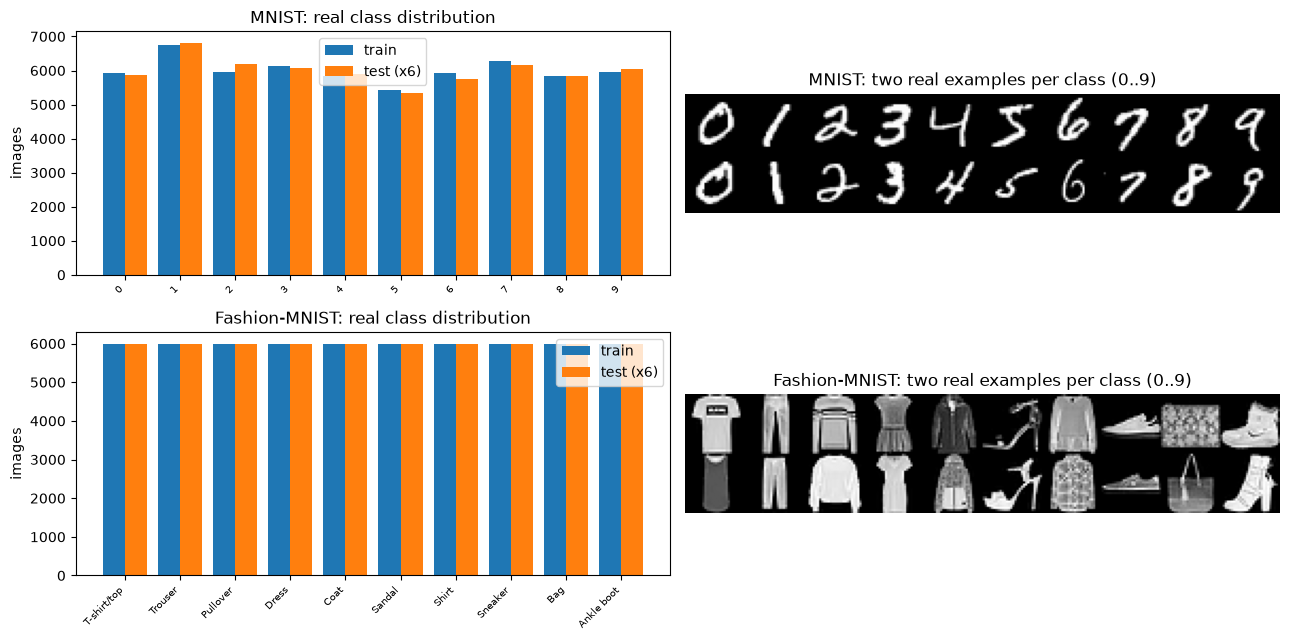

In [5]:
t_ = time.time()
fig, axes = plt.subplots(2, 2, figsize=(13, 6.5))
for r, key in enumerate(DATASETS):
    Xtr, ytr, Xte, yte = RAW[key]; cfg = DATASETS[key]
    feat = [f"pixel_{i}_{j}" for i in range(28) for j in range(28)]
    print(f"== {cfg['title']} ==")
    print("  train images", Xtr.shape, "labels", ytr.shape, "| test images", Xte.shape, "labels", yte.shape)
    print("  features: 784 pixel intensities in [0,1]:", feat[:3], "...", feat[-1], "| pooled to a x a for the models")
    print("  original label values:", np.unique(ytr).tolist(), "=", cfg["names"])
    cnt_tr = np.bincount(ytr, minlength=10); cnt_te = np.bincount(yte, minlength=10)
    print("  train class counts:", dict(zip(cfg["names"], cnt_tr.tolist())))
    print("  test  class counts:", dict(zip(cfg["names"], cnt_te.tolist())))
    ax = axes[r, 0]
    ax.bar(np.arange(10) - 0.2, cnt_tr, 0.4, label="train"); ax.bar(np.arange(10) + 0.2, cnt_te * 6, 0.4, label="test (x6)")
    ax.set_xticks(range(10)); ax.set_xticklabels(cfg["names"], rotation=45, ha="right", fontsize=7)
    ax.set_title(f"{cfg['title']}: real class distribution"); ax.set_ylabel("images"); ax.legend()
    ax = axes[r, 1]
    ex = np.concatenate([np.concatenate([Xtr[np.where(ytr == c)[0][k]] for c in range(10)], 1) for k in range(2)], 0)
    ax.imshow(ex, cmap="gray"); ax.set_title(f"{cfg['title']}: two real examples per class (0..9)"); ax.axis("off")
plt.tight_layout(); plt.show()

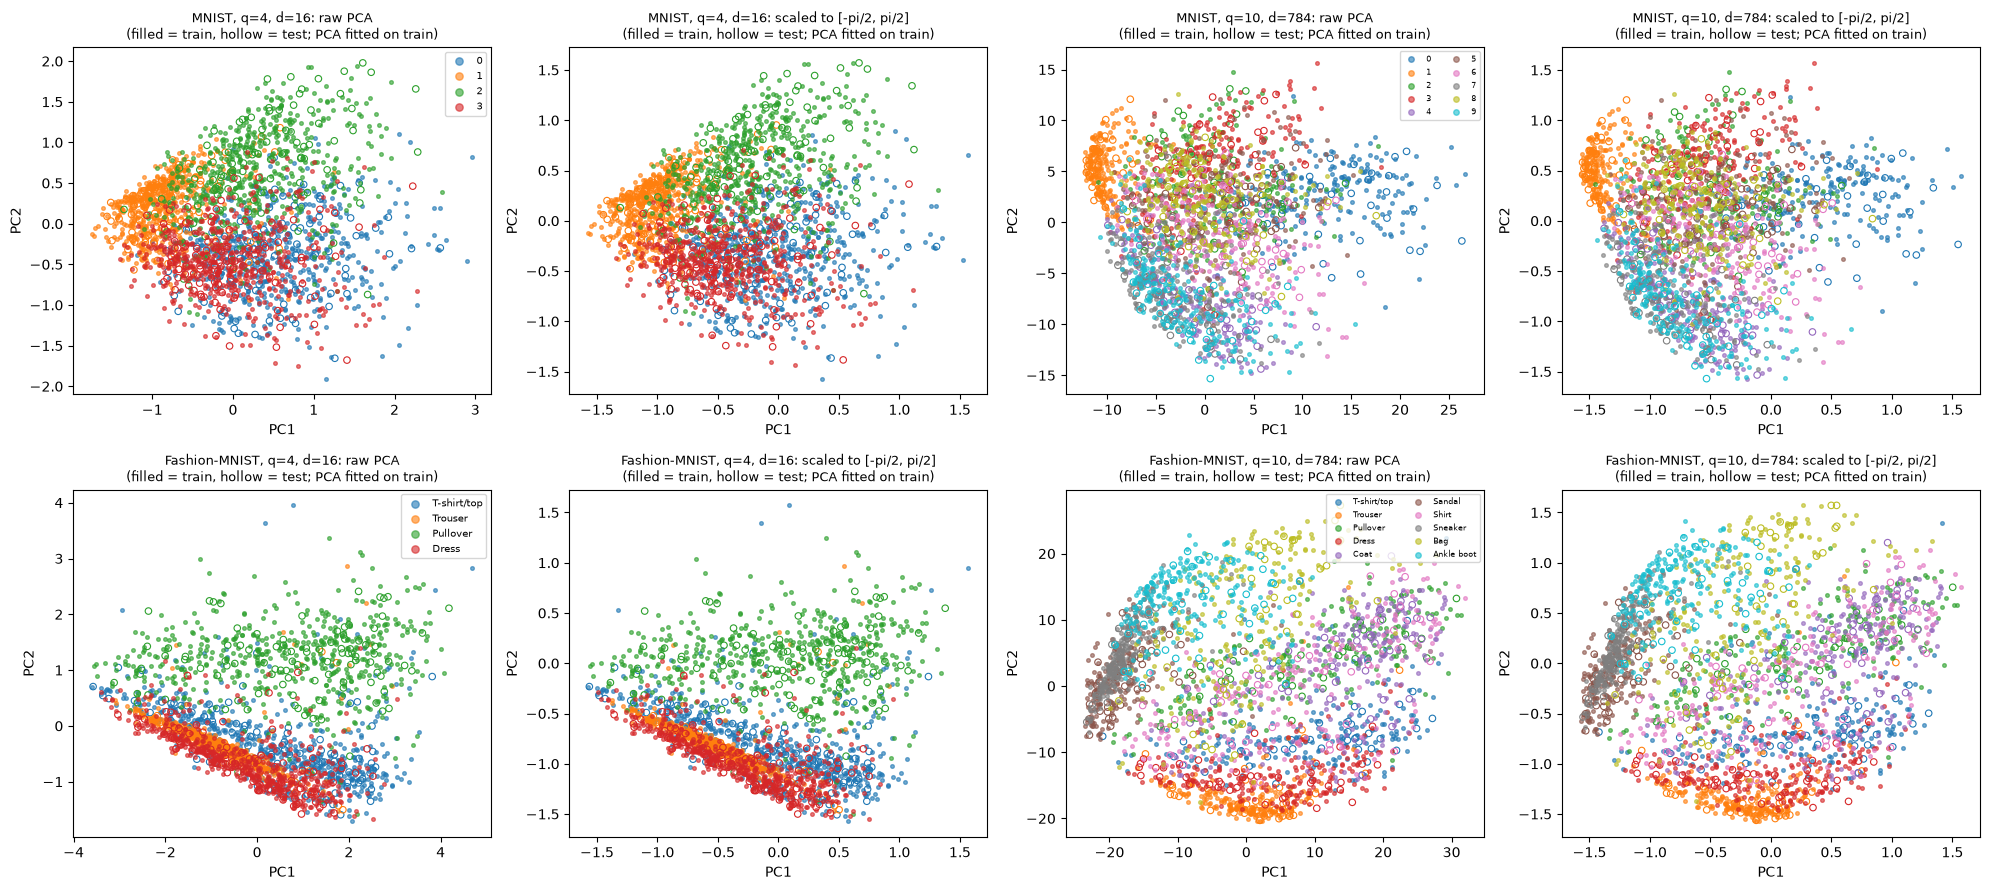

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
cmap = plt.get_cmap("tab10")
for r, key in enumerate(DATASETS):
    cfg = DATASETS[key]
    for k, (q, a) in enumerate([(4, 4), (10, 28)]):
        (xtr, ytr), (xte, yte) = make_split(key, q, a, SEED)
        pca = PCA(n_components=2, random_state=SEED).fit(xtr)               # fitted on the training split only
        ztr, zte = pca.transform(xtr), pca.transform(xte)
        lo, hi = ztr.min(0), ztr.max(0)
        s_tr = (ztr - lo) / (hi - lo) * np.pi - np.pi / 2                    # scaled to the encoding range [-pi/2, pi/2]
        s_te = np.clip((zte - lo) / (hi - lo) * np.pi - np.pi / 2, -np.pi / 2, np.pi / 2)
        for j, (A, B, ttl) in enumerate([(ztr, zte, "raw PCA"), (s_tr, s_te, "scaled to [-pi/2, pi/2]")]):
            ax = axes[r, 2 * k + j]
            for c in range(q):
                m = ytr == c; ax.scatter(A[m, 0], A[m, 1], s=7, color=cmap(c), alpha=0.6, label=cfg["names"][c])
                m = yte == c; ax.scatter(B[m, 0], B[m, 1], s=22, facecolors="none", edgecolors=cmap(c), linewidths=0.8)
            ax.set_title(f"{cfg['title']}, q={q}, d={a*a}: {ttl}\n(filled = train, hollow = test; PCA fitted on train)", fontsize=9)
            ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
            if j == 0 and k == 0: ax.legend(fontsize=7, markerscale=2)
            if j == 0 and k == 1: ax.legend(fontsize=6, markerscale=1.5, ncol=2)
plt.tight_layout(); plt.show()
SECTION_TIMES["data"] = time.time() - t_

## 2. The quantum classifier: QNode, fast exact simulator, training

**The circuit (paper Fig. A1).** For `q` qubits: Hadamard on every wire, the phase-dense encoding as a diagonal unitary `diag(e^{i x_1}, ..., e^{i x_d}, 1, ..., 1)`, then `N_LAYERS` StronglyEntanglingLayers (a general rotation `Rot(phi, theta, omega)` on every wire followed by a ring of CNOTs `CNOT(i, (i + r) mod q)` with range `r = (layer mod (q-1)) + 1`, PennyLane's default), and `<Z_i>` on every wire. The `q` expectation values are the logits. There are `3*q*N_LAYERS` trainable angles (6000 at `q = 10` with 200 layers, as in the paper).

**Why two implementations.** PennyLane (`sel_qnode`) is the reference implementation of the circuit; but training 14 models with 200 layers and attacking them thousands of times with it would take days. `Sim` below is a small exact PyTorch state-vector simulator for exactly this gate list (each layer's single-qubit rotations are fused into two Kronecker-product matrices; the CNOT ring is a basis permutation). Section "Quantum Circuit Architecture" asserts that `Sim` and the QNode agree to `1e-9` for every trained model, so every number in this notebook is a number of the PennyLane circuit.

**Training.** Adam, cross-entropy on the logits, batch 32, lr 0.001 (`q <= 7`) or 0.003 (`q >= 8`), weights drawn from `N(0, 1)`. Training runs in single precision (complex64) for speed; all attacks use the trained weights in double precision.

In [7]:
def cnot_ring_perm(q, r):
    """Gather index for the sequential CNOTs CNOT(i,(i+r)%q), i=0..q-1 (wire 0 = most significant bit)."""
    idx = np.arange(2 ** q)
    bits = (idx[:, None] >> (q - 1 - np.arange(q))[None, :]) & 1
    out = bits.copy()
    for i in range(q):
        out[:, (i + r) % q] ^= out[:, i]
    new_idx = (out * (1 << (q - 1 - np.arange(q)))[None, :]).sum(1)
    inv = np.empty_like(new_idx); inv[new_idx] = np.arange(2 ** q)
    return torch.as_tensor(inv, dtype=torch.long)

def rot_mats(w):
    """PennyLane Rot(phi, theta, omega) matrices for weights w of shape (L, q, 3) -> (L, q, 2, 2)."""
    phi, th, om = w[..., 0], w[..., 1], w[..., 2]
    c, s = torch.cos(th / 2), torch.sin(th / 2)
    e = lambda a: torch.complex(torch.cos(a), torch.sin(a))
    u00, u01 = e(-(phi + om) / 2) * c, -e((phi - om) / 2) * s
    u10, u11 = e(-(phi - om) / 2) * s, e((phi + om) / 2) * c
    return torch.stack([torch.stack([u00, u01], -1), torch.stack([u10, u11], -1)], -2)

def kron_chain(m):
    """(L, n, 2, 2) -> (L, 2^n, 2^n): Kronecker product over the wires, first wire leading."""
    R = m[:, 0]
    for i in range(1, m.shape[1]):
        a = R.shape[1]
        R = torch.einsum("lab,lcd->lacbd", R, m[:, i]).reshape(m.shape[0], a * 2, a * 2)
    return R

class Sim:
    """Exact state-vector simulator of: H^q, phase-dense encoding, L x StronglyEntanglingLayers, <Z_i> read-out."""
    def __init__(self, q, L, dtype=torch.float64):
        self.q, self.L, self.dtype = q, L, dtype
        self.perms = [cnot_ring_perm(q, (l % (q - 1)) + 1) for l in range(L)]
        k = np.arange(2 ** q)
        self.zsign = torch.as_tensor(1 - 2 * ((k[:, None] >> (q - 1 - np.arange(q))[None, :]) & 1), dtype=dtype)   # (2^q, q)
    def encode(self, x):
        B, d = x.shape
        ph = torch.zeros(B, 2 ** self.q, dtype=x.dtype); ph[:, :d] = x
        return torch.complex(torch.cos(ph), torch.sin(ph)) * (2 ** (-self.q / 2))
    def apply(self, psi, w):
        U = rot_mats(w); B = psi.shape[0]; q1 = self.q // 2; q2 = self.q - q1
        Ka, KbT = kron_chain(U[:, :q1]), kron_chain(U[:, q1:]).transpose(1, 2)
        for l in range(self.L):
            psi = torch.matmul(torch.matmul(Ka[l], psi.reshape(B, 2 ** q1, 2 ** q2)), KbT[l]).reshape(B, -1)[:, self.perms[l]]
        return psi
    def probs(self, x, w):
        psi = self.apply(self.encode(x), w)
        return psi.real ** 2 + psi.imag ** 2
    def logits(self, x, w):
        return self.probs(x, w) @ self.zsign

def sel_qnode(q, L, device="default.qubit"):
    """The paper's circuit as a PennyLane QNode (reference implementation)."""
    dev = qml.device(device, wires=q)
    @qml.qnode(dev)
    def circuit(x, w):
        for i in range(q):
            qml.Hadamard(wires=i)                                             # |0> -> |+>
        diag = np.ones(2 ** q, dtype=complex); diag[: len(x)] = np.exp(1j * np.asarray(x))
        qml.DiagonalQubitUnitary(diag, wires=range(q))                         # phase-dense encoding Phi(x)
        qml.StronglyEntanglingLayers(w, wires=range(q))                        # L x (Rot on every wire + CNOT ring)
        return [qml.expval(qml.PauliZ(i)) for i in range(q)]                   # logits = <Z_i>
    return circuit

# quick self-test on random weights before training anything
_q, _L, _d = 5, 6, 25
_w = np.random.default_rng(0).normal(size=(_L, _q, 3)); _x = np.random.default_rng(1).uniform(-1.5, 1.5, _d)
_a = Sim(_q, _L).logits(torch.tensor(_x[None]), torch.tensor(_w)).numpy()[0]; _b = np.array(sel_qnode(_q, _L)(_x, _w))
print("Sim vs QNode on random weights, max |difference| =", float(np.abs(_a - _b).max())); assert np.abs(_a - _b).max() < 1e-9

Sim vs QNode on random weights, max |difference| = 6.661338147750939e-16


In [8]:
def lr_for(q):
    return 1e-3 if q <= 7 else 3e-3          # CHOICE: the paper uses 0.001 for q<=7 and unpublished variants for q=8,9,10

def train_model(key, q, a, seed):
    """Train one (dataset, q) classifier; weights are cached in DATA_DIR."""
    d = a * a
    f = os.path.join(DATA_DIR, f"w_{key}_q{q}_L{N_LAYERS}_s{TRAIN_STEPS}_seed{seed}.npz")
    (xtr, ytr), (xte, yte) = make_split(key, q, a, seed)
    sim32 = Sim(q, N_LAYERS, torch.float32)
    if os.path.exists(f):
        w = np.load(f)["w"]; hist = np.load(f)["hist"]
    else:
        g = torch.Generator().manual_seed(seed)
        w32 = torch.randn(N_LAYERS, q, 3, generator=g, dtype=torch.float32).requires_grad_(True)       # N(0,1) initialisation
        opt = torch.optim.Adam([w32], lr=lr_for(q))
        xt = torch.tensor(xtr, dtype=torch.float32); yt = torch.tensor(ytr); rng = np.random.default_rng(seed); hist = []
        for st in range(TRAIN_STEPS):
            idx = rng.choice(len(xt), BATCH, replace=False)
            loss = torch.nn.functional.cross_entropy(sim32.logits(xt[idx], w32), yt[idx])
            opt.zero_grad(); loss.backward(); opt.step(); hist.append(float(loss.detach()))
        w = w32.detach().numpy().astype(np.float64); hist = np.array(hist)
        np.savez(f, w=w, hist=hist)
    return dict(key=key, q=q, d=d, a=a, L=N_LAYERS, w=w, hist=hist, xtr=xtr, ytr=ytr, xte=xte, yte=yte)

t_ = time.time()
MODELS = {}
for key in DATASETS:
    for q, a in zip(Q_LIST, A_LIST):
        t1 = time.time()
        m = train_model(key, q, a, SEED + q)
        sim = Sim(q, N_LAYERS)
        with torch.no_grad():
            m["acc_te"] = float((sim.logits(torch.tensor(m["xte"]), torch.tensor(m["w"])).argmax(1).numpy() == m["yte"]).mean())
        MODELS[(key, q)] = m
        print(f"{DATASETS[key]['title']:>13} q={q:2d} d={m['d']:3d} layers={N_LAYERS} params={m['w'].size:5d}  last-batch loss={m['hist'][-10:].mean():.3f}  test acc={m['acc_te']:.3f}  ({time.time()-t1:.0f}s)", flush=True)
SECTION_TIMES["training"] = time.time() - t_

        MNIST q= 4 d= 16 layers=200 params= 2400  last-batch loss=1.122  test acc=0.632  (0s)


        MNIST q= 5 d= 25 layers=200 params= 3000  last-batch loss=1.291  test acc=0.772  (1s)


        MNIST q= 6 d= 64 layers=200 params= 3600  last-batch loss=1.452  test acc=0.818  (1s)


        MNIST q= 7 d=121 layers=200 params= 4200  last-batch loss=1.585  test acc=0.867  (2s)


        MNIST q= 8 d=256 layers=200 params= 4800  last-batch loss=1.695  test acc=0.850  (4s)


...

Fashion-MNIST q= 6 d= 64 layers=200 params= 3600  last-batch loss=1.273  test acc=0.778  (1s)


Fashion-MNIST q= 7 d=121 layers=200 params= 4200  last-batch loss=1.464  test acc=0.672  (1s)


Fashion-MNIST q= 8 d=256 layers=200 params= 4800  last-batch loss=1.543  test acc=0.718  (3s)


Fashion-MNIST q= 9 d=484 layers=200 params= 5400  last-batch loss=1.690  test acc=0.646  (5s)


Fashion-MNIST q=10 d=784 layers=200 params= 6000  last-batch loss=1.877  test acc=0.665  (19s)


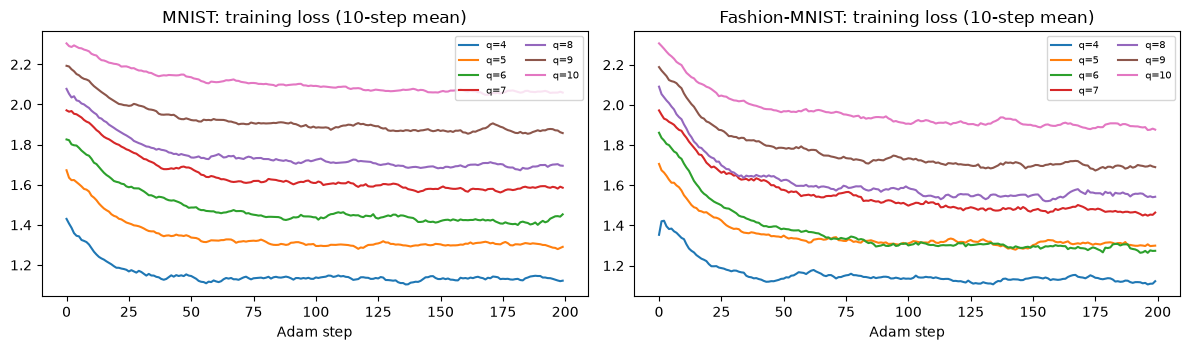

      dataset  q   d  classes  test accuracy  chance
        MNIST  4  16        4          0.632   0.250
        MNIST  5  25        5          0.772   0.200
        MNIST  6  64        6          0.818   0.167
        MNIST  7 121        7          0.867   0.143
        MNIST  8 256        8          0.850   0.125
        MNIST  9 484        9          0.742   0.111
        MNIST 10 784       10          0.677   0.100
Fashion-MNIST  4  16        4          0.590   0.250
Fashion-MNIST  5  25        5          0.705   0.200
Fashion-MNIST  6  64        6          0.778   0.167
Fashion-MNIST  7 121        7          0.672   0.143
Fashion-MNIST  8 256        8          0.718   0.125
Fashion-MNIST  9 484        9          0.646   0.111
Fashion-MNIST 10 784       10          0.665   0.100


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for i, key in enumerate(DATASETS):
    for q in Q_LIST:
        h = MODELS[(key, q)]["hist"]; ax[i].plot(pd.Series(h).rolling(10, min_periods=1).mean(), label=f"q={q}")
    ax[i].set_title(f"{DATASETS[key]['title']}: training loss (10-step mean)"); ax[i].set_xlabel("Adam step"); ax[i].legend(ncol=2, fontsize=7)
plt.tight_layout(); plt.show()
print(pd.DataFrame([{"dataset": DATASETS[k]["title"], "q": q, "d": MODELS[(k, q)]["d"], "classes": q, "test accuracy": round(MODELS[(k, q)]["acc_te"], 3),
                     "chance": round(1 / q, 3)} for (k, q) in MODELS]).to_string(index=False))

## Hardware-efficient model for the hardware experiment (trained here, attacked in section 8)

The paper's hardware experiment (Appendix B, Fig. B1) uses a different and much shallower circuit so that it fits on a real device: **4 qubits, `d = 12` features** (`3 x 4` down-sampled MNIST), three `RX(x)` feature-upload blocks (4 features each, one per qubit) interleaved with **15 hardware-efficient (HWE) layers** in the pattern `3 HWE, RX, 3 HWE, RX, 3 HWE, RX, 6 HWE`. One HWE layer is a column of `Rot` gates, a two-step brick of parametric `RZZ` entanglers (pairs (0,1), (2,3), then (1,2)) and a closing column of `Rot` gates: 27 trainable angles per layer, 405 in total. Only the two middle qubits are read out; the binary label is the sign of the margin `<Z_1> - <Z_2>`. The paper trains it on an ideal simulator and transfers it to the device unchanged; we do the same on `default.qubit` (digits 0 vs 1, a CHOICE because the paper does not name the pair).

In [10]:
dev_hw = qml.device("default.qubit", wires=4)
def hwe_layer(p):
    for i in range(4): qml.Rot(p[3 * i], p[3 * i + 1], p[3 * i + 2], wires=i)
    qml.IsingZZ(p[12], wires=[0, 1]); qml.IsingZZ(p[13], wires=[2, 3]); qml.IsingZZ(p[14], wires=[1, 2])      # RZZ brick: even pairs, then odd pair
    for i in range(4): qml.Rot(p[15 + 3 * i], p[16 + 3 * i], p[17 + 3 * i], wires=i)

@qml.qnode(dev_hw, interface="torch", diff_method="backprop")
def hwe(x, w):
    """4-qubit HWE classifier: 3 RX upload blocks (4 features each), 15 HWE layers, probabilities of all 4 qubits."""
    l = 0
    for blk, n_l in enumerate((3, 3, 3, 6)):
        for _ in range(n_l):
            hwe_layer(w[l]); l += 1
        if blk < 3:
            for i in range(4): qml.RX(x[..., 4 * blk + i], wires=i)
    return qml.probs(wires=range(4))

ZS4 = torch.tensor([[1 - 2 * ((k >> (3 - i)) & 1) for i in range(4)] for k in range(16)], dtype=torch.float64)    # Z eigenvalues per outcome
HW_MARGIN_VEC = ZS4[:, 1] - ZS4[:, 2]                                                                            # <Z_1> - <Z_2>
HW_CLASSES = (0, 1)

def pool34(X):
    r = [(int(np.floor(i * 28 / 3)), int(np.ceil((i + 1) * 28 / 3))) for i in range(3)]
    c = [(int(np.floor(i * 28 / 4)), int(np.ceil((i + 1) * 28 / 4))) for i in range(4)]
    rows = np.stack([X[:, s:e, :].mean(1) for s, e in r], 1)
    return np.stack([rows[:, :, s:e].mean(2) for s, e in c], 2)

def hw_split(seed=SEED, n_tr=600, n_te=400):
    Xtr, ytr, Xte, yte = RAW["mnist"]; rng = np.random.default_rng(seed)
    def sub(X, y, n):
        idx = np.concatenate([rng.permutation(np.where(y == c)[0])[: n // 2] for c in HW_CLASSES]); rng.shuffle(idx)
        return to_angles(pool34(X[idx])).reshape(len(idx), -1).astype(np.float64), (y[idx] == HW_CLASSES[1]).astype(int)
    return sub(Xtr, ytr, n_tr), sub(Xte, yte, n_te)

def hw_margin(x, w):
    return hwe(x, w) @ HW_MARGIN_VEC

t_ = time.time()
(xhtr, yhtr), (xhte, yhte) = hw_split()
f_hw = os.path.join(DATA_DIR, f"hwe_w_s{HW_TRAIN_STEPS}.npy")
if os.path.exists(f_hw):
    w_hw = torch.tensor(np.load(f_hw))
else:
    torch.manual_seed(SEED); w_hw = (0.5 * torch.randn(15, 27, dtype=torch.float64)).requires_grad_(True)
    opt = torch.optim.Adam([w_hw], lr=0.03); xt = torch.tensor(xhtr); yt = torch.tensor(2.0 * yhtr - 1); rng = np.random.default_rng(SEED)
    for st in range(HW_TRAIN_STEPS):
        idx = rng.choice(len(xt), 32, replace=False)
        loss = torch.nn.functional.softplus(-yt[idx] * hw_margin(xt[idx], w_hw)).mean()      # = 2-class softmax CE on (<Z1>,<Z2>)
        opt.zero_grad(); loss.backward(); opt.step()
    w_hw = w_hw.detach(); np.save(f_hw, w_hw.numpy())
with torch.no_grad():
    m_te = hw_margin(torch.tensor(xhte), w_hw).numpy()
acc_hw = float(((m_te > 0) == yhte).mean())
print(f"HWE model (digits {HW_CLASSES[0]} vs {HW_CLASSES[1]}, d=12, 405 trainable angles): test accuracy = {acc_hw:.3f}  ({time.time()-t_:.0f}s)")
SECTION_TIMES["hwe training"] = time.time() - t_

HWE model (digits 0 vs 1, d=12, 405 trainable angles): test accuracy = 0.980  (1s)


## Quantum Circuit Architecture

Two distinct gate-based architectures are trained and attacked in this notebook:

1. the **SEL classifier** of Appendix A (`q = 4 ... 10` qubits, phase-dense encoding, `N_LAYERS` strongly-entangling layers, Pauli-Z read-out);
2. the **HWE classifier** of Appendix B (4 qubits, 3 `RX` uploads, 15 hardware-efficient layers, margin read-out of the middle two qubits).

Below we draw the PennyLane QNodes with the *trained* weights and a real test input, then print qubit count, depth and trainable-parameter count of the circuits **as executed** (the full `N_LAYERS`, decomposed to the gates the device runs). For the SEL circuit the picture shows the first four layers only (a 200-layer drawing is unreadable); it is produced by the same `sel_qnode` builder as the executed circuit, and the equivalence assertion at the end of this section checks the *full-depth* trained circuit against the fast simulator that all attacks use. **Assumptions where the paper is silent:** the Hadamards before the encoding and the CNOT ranges follow PennyLane's `StronglyEntanglingLayers` default; the `Rot` angle order is PennyLane's `(phi, theta, omega)`; `RZZ` is `IsingZZ`; the order of the 12 pixels over the 3 uploads is row-major (pixels 0-3, 4-7, 8-11 to qubits 0-3).

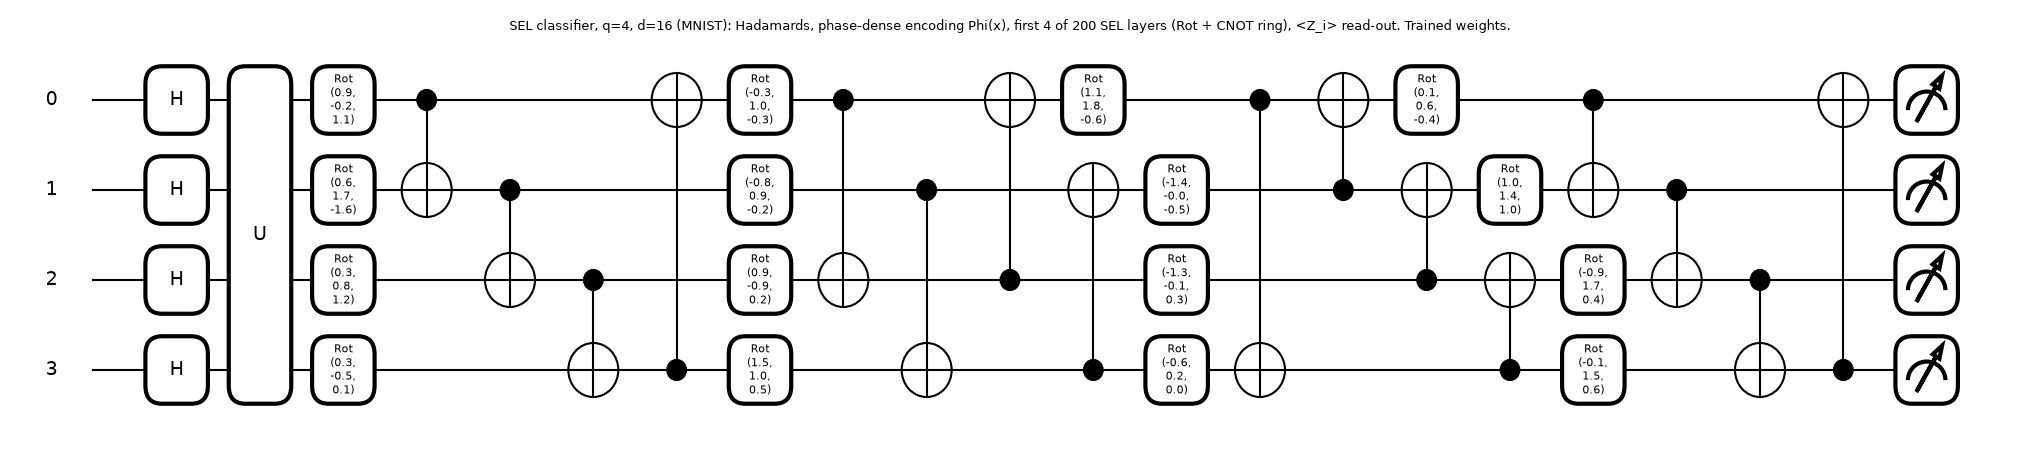

fig.1 drawn


       circuit  qubits  layers  executed depth (device level)  gates  Rot gates  CNOT  trainable parameters
SEL classifier       4     200                            802   1605        800   800                  2400
SEL classifier       5     200                            854   2006       1000  1000                  3000
SEL classifier       6     200                            885   2407       1200  1200                  3600
SEL classifier       7     200                            939   2808       1400  1400                  4200
SEL classifier       8     200                            975   3209       1600  1600                  4800
SEL classifier       9     200                           1008   3610       1800  1800                  5400
SEL classifier      10     200                           1031   4011       2000  2000                  6000
HWE classifier       4      15                             63    177        120     0                   405
HWE gate types: {'Rot': 120,

In [11]:
t_ = time.time()
m4 = MODELS[("mnist", 4)]
L_DRAW = min(4, N_LAYERS)
qn_draw = sel_qnode(4, L_DRAW)
fig, ax = qml.draw_mpl(qn_draw, level="device", decimals=1)(m4["xte"][0], m4["w"][:L_DRAW])
fig.suptitle(f"SEL classifier, q=4, d=16 (MNIST): Hadamards, phase-dense encoding Phi(x), first {L_DRAW} of {N_LAYERS} SEL layers (Rot + CNOT ring), <Z_i> read-out. Trained weights.", fontsize=9)
fig.set_size_inches(min(30, 8 + 3 * L_DRAW), 4.5); plt.show()
print("fig.1 drawn")

rows = []
for q in Q_LIST:
    m = MODELS[("mnist", q)]
    sp = qml.specs(sel_qnode(q, N_LAYERS), level="device")(m["xte"][0], m["w"])
    gt = sp.resources.gate_types
    rows.append({"circuit": "SEL classifier", "qubits": q, "layers": N_LAYERS, "executed depth (device level)": sp.resources.depth,
                 "gates": sp.resources.num_gates, "Rot gates": gt.get("Rot", 0), "CNOT": gt.get("CNOT", 0),
                 "trainable parameters": m["w"].size})
    assert m["w"].size == 3 * q * N_LAYERS == 3 * gt.get("Rot", 0)
spw = qml.specs(hwe, level="device")(torch.tensor(xhte[0]), w_hw)
gt = spw.resources.gate_types
rows.append({"circuit": "HWE classifier", "qubits": 4, "layers": 15, "executed depth (device level)": spw.resources.depth, "gates": spw.resources.num_gates,
             "Rot gates": gt.get("Rot", 0), "CNOT": gt.get("CNOT", 0), "trainable parameters": int(w_hw.numel())})
assert int(w_hw.numel()) == 3 * gt.get("Rot", 0) + gt.get("IsingZZ", 0) == 405
print(pd.DataFrame(rows).to_string(index=False))
print("HWE gate types:", dict(gt))

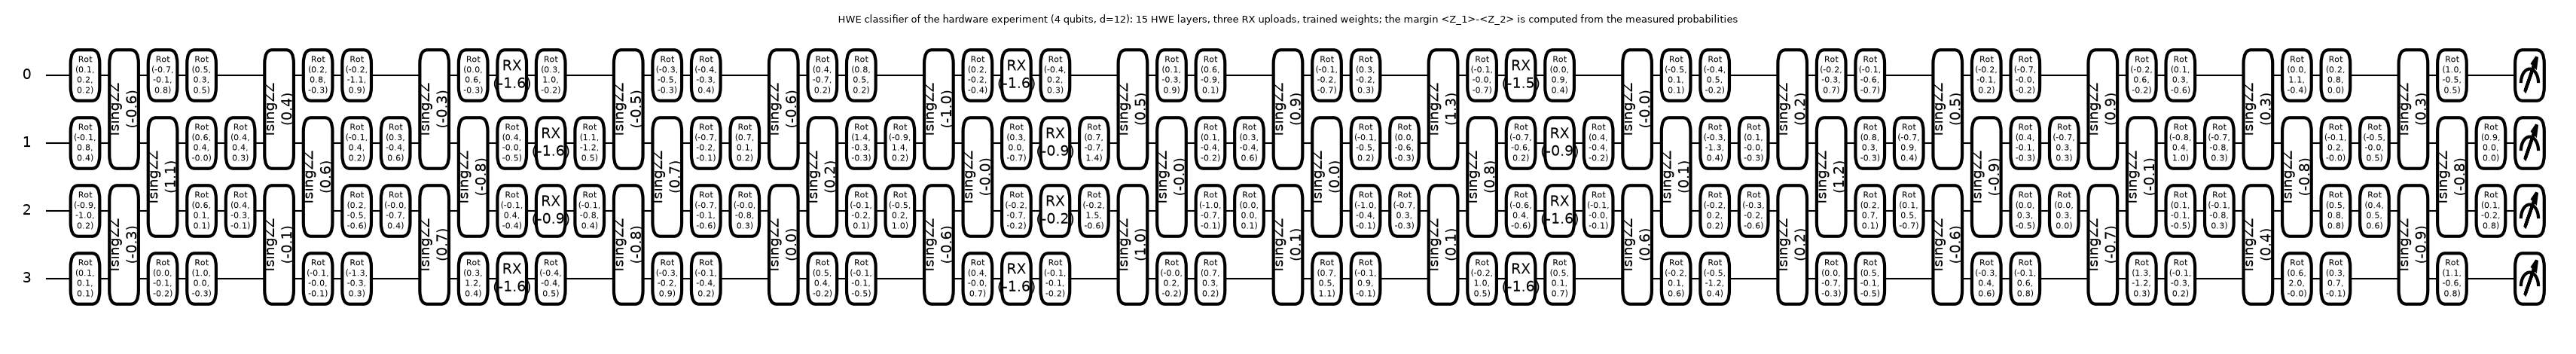

fig.2 drawn


max |Sim - QNode| over the logits: [('mnist', 4, 2.6645352591003757e-15), ('mnist', 5, 1.0547118733938987e-15), ('mnist', 6, 1.7208456881689926e-15), ('mnist', 7, 8.326672684688674e-16), ('mnist', 8, 1.5543122344752192e-15), ('mnist', 9, 6.800116025829084e-16), ('mnist', 10, 1.2212453270876722e-15), ('fashion', 4, 2.831068712794149e-15), ('fashion', 7, 3.1086244689504383e-15), ('fashion', 10, 3.164135620181696e-15)]
OK: fast simulator == PennyLane QNode (full depth, trained weights)


In [12]:
fig, ax = qml.draw_mpl(hwe, level="device", decimals=1)(torch.tensor(xhte[0]), w_hw)
fig.suptitle("HWE classifier of the hardware experiment (4 qubits, d=12): 15 HWE layers, three RX uploads, trained weights; "
             "the margin <Z_1>-<Z_2> is computed from the measured probabilities", fontsize=9)
fig.set_size_inches(34, 4.5); plt.show()
print("fig.2 drawn")

# Equivalence: the fast simulator used for all attacks == the PennyLane QNode, at full executed depth, with the trained weights.
errs = []
for (key, q), m in MODELS.items():
    if key != "mnist" and q not in (4, 7, 10): continue
    x = m["xte"][0]
    a = Sim(q, N_LAYERS).logits(torch.tensor(x[None]), torch.tensor(m["w"])).numpy()[0]
    b = np.array(sel_qnode(q, N_LAYERS)(x, m["w"]))
    errs.append((key, q, float(np.abs(a - b).max())))
print("max |Sim - QNode| over the logits:", errs)
assert max(e[2] for e in errs) < 1e-9, "simulator and QNode disagree"
print("OK: fast simulator == PennyLane QNode (full depth, trained weights)")
SECTION_TIMES["circuit section"] = time.time() - t_

## 3. The attacker's gradient: exact PSR moments and finite shots

For a classical input `x`, the model output `f_c(x) = <Z_c>` is the expectation of a `+-1` observable. The loss is the softmax cross entropy of the `q` logits and the attacker needs `g = grad_x L(x, y) = sum_c (P_c - 1[c=y]) * grad_x f_c`.

**Parameter-shift rule.** Feature `x_j` enters through the gate `e^{i x_j |j><j|}`. The generator `|j><j|` has eigenvalues `{0, 1}` (gap 1), so
`d f / d x_j = [ f(x + pi/2 e_j) - f(x - pi/2 e_j) ] / 2`
(paper Eq. 1 and Appendix D). The attacker runs the two shifted circuits, each with `s/2` shots (`s` shots per input dimension, total `R = d*s`), and measures all `q` Pauli-Z at once, so a single bitstring `b` gives one sample of `S(b) = sum_c w_c z_c(b)` with `w_c = P_c - 1[c = y]` (z_c(b) = the +-1 outcome of qubit `c`).

**Exact moments.** Shifting `x_j` by `+-pi/2` multiplies the amplitude of basis state `j` before the circuit unitary `A` by `+-i`. With `A` (the `2^q x 2^q` unitary of the trained circuit, obtained once by running the simulator on all basis states) all `2d` shifted output distributions are available at once, so the *exact* mean `mu_j^+-` and variance `V_j^+-` of `S` per shot are known. The shot-limited PSR estimate is then, for large `s`, Gaussian: `g_hat_j ~ N(g_j, sigma_j^2 / s)` with `sigma_j^2 = (V_j^+ + V_j^-) / 2` (paper: `Var[g_hat_i] = sigma^2/s`). The paper reports `sigma^2 ~ 3`, flat in `d`. Section 5 checks this Gaussian model against explicit multinomial bitstring sampling of the shifted circuits.

In [13]:
AT_CACHE = {}
def get_At(m):
    k = (m["key"], m["q"])
    if k not in AT_CACHE: AT_CACHE[k] = Attackable(m)
    return AT_CACHE[k]

class Attackable:
    """Everything the attacker needs about one trained (dataset, q) model, in double precision."""
    def __init__(self, m):
        self.m = m; self.q, self.d, self.L = m["q"], m["d"], m["L"]
        self.N = 2 ** self.q
        sim = Sim(self.q, self.L)
        w = torch.tensor(m["w"], dtype=torch.float64)
        with torch.no_grad():
            out = sim.apply(torch.eye(self.N, dtype=torch.complex128), w)      # row k = circuit applied to basis state |k>
        self.A = out.T.contiguous().numpy()                                    # (N, N) unitary of the trained circuit
        self.Z = sim.zsign.numpy()                                             # (N, q) +-1 outcomes of every qubit
        self.eps = KAPPA * np.sqrt(self.d)
        self.sim, self.w = sim, w
    def psi(self, x):
        ph = np.zeros(self.N); ph[: self.d] = x
        return np.exp(1j * ph) * self.N ** -0.5
    def forward(self, x):
        """exact output distribution over bitstrings, logits <Z_c>, amplitudes"""
        amp = self.A @ self.psi(x); p = amp.real ** 2 + amp.imag ** 2
        return amp, p, p @ self.Z
    def loss_logits(self, X, Y):
        """batch: cross entropy and logits for inputs X (n, d)"""
        n = len(X); ph = np.zeros((n, self.N)); ph[:, : self.d] = X
        amp = (np.exp(1j * ph) * self.N ** -0.5) @ self.A.T; p = amp.real ** 2 + amp.imag ** 2
        z = p @ self.Z; z = z - z.max(1, keepdims=True)
        logp = z - np.log(np.exp(z).sum(1, keepdims=True))
        return -logp[np.arange(n), Y], p @ self.Z
    def psr_moments(self, x, amp, wv):
        """Exact PSR gradient of  sum_c wv_c <Z_c>  and per-shot variance sigma_j^2 for every input dimension j."""
        S = self.Z @ wv                                                     # S(b) for every outcome b
        c = np.exp(1j * x) * self.N ** -0.5
        Apj = self.A[:, : self.d] * c[None, :]                              # effect of the phase of feature j on the output amplitudes
        ap, am = amp[:, None] + (1j - 1) * Apj, amp[:, None] + (-1j - 1) * Apj     # x_j +- pi/2
        pp, pm = ap.real ** 2 + ap.imag ** 2, am.real ** 2 + am.imag ** 2
        mup, mum = S @ pp, S @ pm; vp, vm = (S ** 2) @ pp - mup ** 2, (S ** 2) @ pm - mum ** 2
        return (mup - mum) / 2, (vp + vm) / 2, None

def ce_weights(z, y):
    P = np.exp(z - z.max()); P /= P.sum(); wv = P.copy(); wv[y] -= 1; return wv

# ---- validation 1: analytic PSR gradient == PyTorch autograd gradient of the cross entropy, per sample ----
mv = MODELS[("mnist", 4)]; At = get_At(mv)
x0, y0 = mv["xte"][3], int(mv["yte"][3])
amp, p, z = At.forward(x0)
g_psr, sig2, _ = At.psr_moments(x0, amp, ce_weights(z, y0))
xt_ = torch.tensor(x0[None], requires_grad=True)
torch.nn.functional.cross_entropy(At.sim.logits(xt_, At.w), torch.tensor([y0])).backward()
print("max |PSR gradient - autograd gradient| (q=4, d=16):", float(np.abs(g_psr - xt_.grad.numpy()[0]).max()))
assert np.abs(g_psr - xt_.grad.numpy()[0]).max() < 1e-9
print("per-shot variance sigma_j^2, first 8 components:", np.round(sig2[:8], 3), "| mean", round(float(sig2.mean()), 3))

max |PSR gradient - autograd gradient| (q=4, d=16): 7.771561172376096e-16
per-shot variance sigma_j^2, first 8 components: [0.778 0.87  0.751 0.859 0.964 0.832 0.835 0.808] | mean 0.826


In [14]:
# ---- validation 2: Gaussian (CLT) shot model  vs  explicit multinomial bitstring sampling of the 2d shifted circuits ----
def sampled_psr_gradient(At, x, amp, wv, s, rng):
    """Explicit finite-shot PSR: s/2 bitstring samples from every shifted circuit, S(b) averaged, differenced."""
    S = At.Z @ wv; c = np.exp(1j * x) * At.N ** -0.5; Apj = At.A[:, : At.d] * c[None, :]
    g = np.zeros(At.d)
    for sign, col in ((+1, 0), (-1, 1)):
        a_ = amp[:, None] + (sign * 1j - 1) * Apj; p_ = (a_.real ** 2 + a_.imag ** 2).T            # (d, N)
        p_ = p_ / p_.sum(1, keepdims=True)
        counts = rng.multinomial(int(s // 2), p_)                                                  # (d, N) bitstring histograms
        mean_S = counts @ S / (s // 2)
        g += sign * mean_S / 2
    return g

rngv = np.random.default_rng(SEED)
rows = []
for (key, q) in [("mnist", 4), ("fashion", 5)]:
    At_ = get_At(MODELS[(key, q)]); mm = MODELS[(key, q)]
    x0, y0 = mm["xte"][1], int(mm["yte"][1]); amp, p, z = At_.forward(x0); wv = ce_weights(z, y0)
    g_ex, s2, _ = At_.psr_moments(x0, amp, wv)
    for s in (400, 4000, 40000):
        samp = np.stack([sampled_psr_gradient(At_, x0, amp, wv, s, rngv) for _ in range(300)])
        clt = g_ex[None] + np.sqrt(s2 / s)[None] * rngv.normal(size=(300, At_.d))
        cos = lambda G: float(np.mean(G @ g_ex / (np.linalg.norm(G, axis=1) * np.linalg.norm(g_ex))))
        rows.append({"model": f"{key} q={q}", "s per dim": s, "max z-score of the bias": float(np.max(np.abs(samp.mean(0) - g_ex) / (samp.std(0) / np.sqrt(300)))),
                     "std ratio multinomial/CLT (median over j)": float(np.median(samp.std(0) / clt.std(0))),
                     "cosine to exact g: multinomial": cos(samp), "cosine to exact g: CLT": cos(clt)})
print(pd.DataFrame(rows).round(3).to_string(index=False))

      model  s per dim  max z-score of the bias  std ratio multinomial/CLT (median over j)  cosine to exact g: multinomial  cosine to exact g: CLT
  mnist q=4        400                    1.946                                      0.991                           0.907                   0.905
  mnist q=4       4000                    1.763                                      0.979                           0.989                   0.989
  mnist q=4      40000                    1.895                                      0.994                           0.999                   0.999
fashion q=5        400                    2.390                                      1.008                           0.750                   0.754
fashion q=5       4000                    3.432                                      1.035                           0.964                   0.966
fashion q=5      40000                    3.030                                      1.019                           0

## 4. Single-step FGSM: how does the shortfall depend on the shot budget? (paper Section 4.1.1, Fig. 2, Fig. 3)

For every test sample we compute the exact gradient `g*`, then for each shot budget `s` a noisy estimate `g_hat`, and perturb with the l2 FGSM step `delta = eps * g_hat / ||g_hat||`, `eps = sqrt(d)/32`. The **loss shortfall** is `Delta L(s) = L(x + delta*) - L(x + delta_s)` where `delta*` uses the exact gradient; we also record the adversarial accuracy. Shot budgets are `s = h * s*` for 8 log-spaced multiples `h in [0.3, 12]` of the critical count `s* = (d-1) sigma^2 / (2 ||g*||^2)` (the budget at which the gradient signal-to-noise ratio reaches one; `sigma^2` and `||g*||^2` are cohort means from the exact moments, the paper's "probe measurements"). The through-origin fit `Delta L = B_q / s` uses the in-regime points `h >= 1`.

In [15]:
def attack_cohort(m, n_attack):
    """balanced per-class cohort of test samples"""
    q = m["q"]; per = max(1, n_attack // q); idx = []
    for c in range(q): idx += list(np.where(m["yte"] == c)[0][:per])
    return np.array(idx)

def fgsm_sweep(At, idx, seed):
    m = At.m; X, Y = m["xte"][idx], m["yte"][idx]; n = len(idx); d = At.d; rng = np.random.default_rng(seed)
    G = np.zeros((n, d)); S2 = np.zeros((n, d)); L0 = np.zeros(n)
    for i in range(n):
        amp, p, z = At.forward(X[i]); wv = ce_weights(z, Y[i])
        G[i], S2[i], _ = At.psr_moments(X[i], amp, wv)
    gn = np.linalg.norm(G, axis=1); eps = At.eps
    L0, lg0 = At.loss_logits(X, Y)
    Lx, lgx = At.loss_logits(X + eps * G / gn[:, None], Y)                       # exact-gradient FGSM
    acc_clean = float((lg0.argmax(1) == Y).mean()); acc_exact = float((lgx.argmax(1) == Y).mean())
    sig2 = float(S2.mean()); s_star = (d - 1) * sig2 / (2 * float(np.mean(gn ** 2)))
    s_grid = H_GRID * s_star
    gap = np.zeros((len(s_grid), n)); acc = np.zeros(len(s_grid))
    for k, s in enumerate(s_grid):
        for r in range(N_REAL):
            Gh = G + np.sqrt(S2 / s) * rng.normal(size=G.shape)                     # s shots per dimension (both PSR shifts included)
            Ls, lgs = At.loss_logits(X + eps * Gh / np.linalg.norm(Gh, axis=1, keepdims=True), Y)
            gap[k] += (Lx - Ls) / N_REAL; acc[k] += float((lgs.argmax(1) == Y).mean()) / N_REAL
    zeta = (Lx - L0) / (eps * gn)                                                   # landscape factor: realised rise / first-order rise
    return dict(d=d, q=At.q, n=n, eps=eps, s_star=s_star, s_grid=s_grid, gap=gap, acc=acc, acc_exact=acc_exact, acc_clean=acc_clean,
                gnorm=gn, sig2_i=S2.mean(1), zeta_i=zeta, L0=L0, Lx=Lx)

t_ = time.time()
SWEEP = {}
for key in DATASETS:
    for q in Q_LIST:
        t1 = time.time(); m = MODELS[(key, q)]
        At = get_At(m)
        SWEEP[(key, q)] = fgsm_sweep(At, attack_cohort(m, N_ATTACK), SEED + 100 * q)
        r = SWEEP[(key, q)]
        print(f"{DATASETS[key]['title']:>13} q={q:2d} d={m['d']:3d}  n={r['n']}  <||g*||>={r['gnorm'].mean():.4f}  sigma^2={r['sig2_i'].mean():.2f}  s*={r['s_star']:.3g}  "
              f"acc clean/exact-attack={r['acc_clean']:.2f}/{r['acc_exact']:.2f}  ({time.time()-t1:.0f}s)", flush=True)
SECTION_TIMES["fgsm sweep"] = time.time() - t_

        MNIST q= 4 d= 16  n=200  <||g*||>=0.3722  sigma^2=0.67  s*=35.6  acc clean/exact-attack=0.64/0.56  (0s)

        MNIST q= 5 d= 25  n=200  <||g*||>=0.2602  sigma^2=0.73  s*=127  acc clean/exact-attack=0.78/0.70  (1s)


        MNIST q= 6 d= 64  n=198  <||g*||>=0.1566  sigma^2=0.68  s*=860  acc clean/exact-attack=0.84/0.80  (1s)


        MNIST q= 7 d=121  n=196  <||g*||>=0.1056  sigma^2=0.71  s*=3.76e+03  acc clean/exact-attack=0.86/0.79  (2s)


        MNIST q= 8 d=256  n=200  <||g*||>=0.0709  sigma^2=0.74  s*=1.86e+04  acc clean/exact-attack=0.84/0.78  (9s)


...

Fashion-MNIST q= 6 d= 64  n=198  <||g*||>=0.1470  sigma^2=0.50  s*=703  acc clean/exact-attack=0.75/0.72  (1s)


Fashion-MNIST q= 7 d=121  n=196  <||g*||>=0.1046  sigma^2=0.55  s*=2.9e+03  acc clean/exact-attack=0.71/0.67  (2s)


Fashion-MNIST q= 8 d=256  n=200  <||g*||>=0.0683  sigma^2=0.52  s*=1.36e+04  acc clean/exact-attack=0.73/0.69  (11s)


Fashion-MNIST q= 9 d=484  n=198  <||g*||>=0.0503  sigma^2=0.60  s*=5.49e+04  acc clean/exact-attack=0.61/0.58  (37s)


Fashion-MNIST q=10 d=784  n=200  <||g*||>=0.0324  sigma^2=0.68  s*=2.51e+05  acc clean/exact-attack=0.67/0.62  (122s)


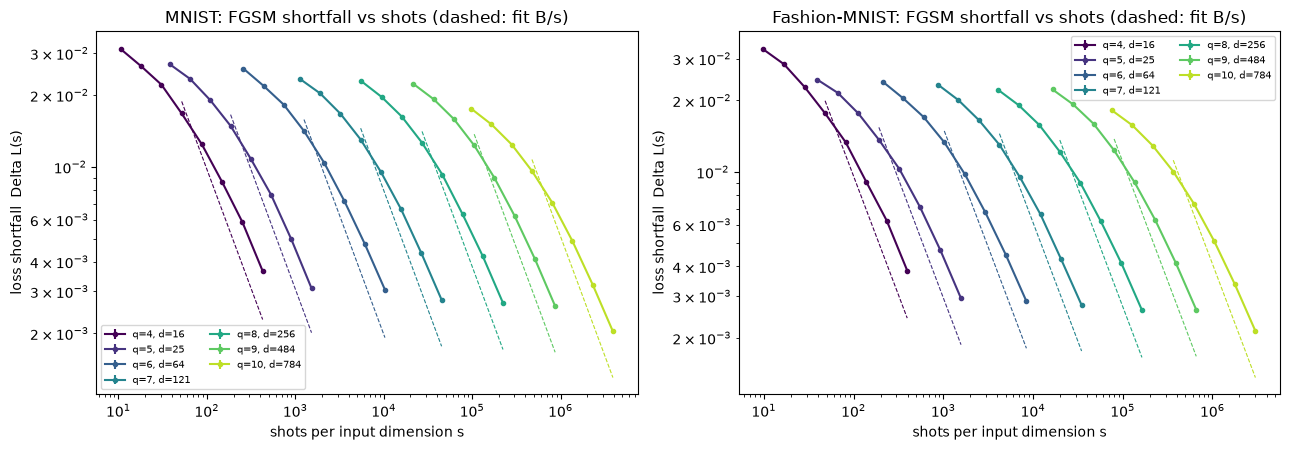

log-log slope of Delta L(s) over all 14 models, window h>=1: mean -0.734 (min -0.743, max -0.720);  small-noise window h>=6: mean -0.869 (min -0.921, max -0.843)   (paper: -1)
(at h~1 the gradient estimate is not yet in the small-noise regime, so the shortfall saturates and the h>=1 slope is shallower than -1)


In [16]:
def fit_B(r, hmin=1.0):
    """through-origin fit  Delta L = B/s  on the in-regime points h >= hmin (mean over samples)"""
    ok = H_GRID >= hmin; s = r["s_grid"][ok]; y = r["gap"][ok].mean(1)
    return float(np.sum(y / s) / np.sum(1 / s ** 2))

def powerlaw(dv, yv):
    dv, yv = np.asarray(dv, float), np.asarray(yv, float)
    res = stats.linregress(np.log(dv), np.log(yv)); n = len(dv); tcrit = stats.t.ppf(0.975, n - 2)
    return dict(slope=res.slope, lo=res.slope - tcrit * res.stderr, hi=res.slope + tcrit * res.stderr, r2=res.rvalue ** 2, prefactor=float(np.exp(res.intercept)))

colors = plt.cm.viridis(np.linspace(0, 0.9, len(Q_LIST)))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, key in zip(axes, DATASETS):
    for c, q in zip(colors, Q_LIST):
        r = SWEEP[(key, q)]; y = r["gap"].mean(1); se = r["gap"].std(1) / np.sqrt(r["n"])
        ax.errorbar(r["s_grid"], np.maximum(y, 1e-12), yerr=se, marker="o", ms=3, color=c, label=f"q={q}, d={r['d']}")
        B = fit_B(r); sg = r["s_grid"][H_GRID >= 1]; ax.plot(sg, B / sg, "--", color=c, lw=0.8)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("shots per input dimension s"); ax.set_ylabel("loss shortfall  Delta L(s)")
    ax.set_title(f"{DATASETS[key]['title']}: FGSM shortfall vs shots (dashed: fit B/s)"); ax.legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

# 1/s law: log-log slope of Delta L versus s on the in-regime points, per q
sl = []
for key in DATASETS:
    for q in Q_LIST:
        r = SWEEP[(key, q)]; ok = H_GRID >= 1
        sl.append(stats.linregress(np.log(r["s_grid"][ok]), np.log(r["gap"][ok].mean(1))).slope)
sl6 = []
for key in DATASETS:
    for q in Q_LIST:
        r = SWEEP[(key, q)]; ok = H_GRID >= 6
        sl6.append(stats.linregress(np.log(r["s_grid"][ok]), np.log(r["gap"][ok].mean(1))).slope)
print("log-log slope of Delta L(s) over all 14 models, window h>=1: mean %.3f (min %.3f, max %.3f);  small-noise window h>=6: mean %.3f (min %.3f, max %.3f)   (paper: -1)" % (np.mean(sl), np.min(sl), np.max(sl), np.mean(sl6), np.min(sl6), np.max(sl6)))
print("(at h~1 the gradient estimate is not yet in the small-noise regime, so the shortfall saturates and the h>=1 slope is shallower than -1)")

==== MNIST ====
 q   d  B_q (loss*shots)  <||g*||>  sigma^2  zeta  B*<||g*||>  semi-analytic 0.5 eps (d-1) sigma^2 zeta  measured B / semi-analytic B
 4  16            0.9756    0.3722   0.6735 1.018      0.3631                                    0.6417                        0.5677
 5  25             3.068    0.2602   0.7297  1.02      0.7984                                     1.393                        0.5751
 6  64              19.8    0.1566   0.6841 1.022       3.101                                     5.498                        0.5674
 7 121             79.61    0.1056   0.7077  1.02       8.403                                     14.87                        0.5674
 8 256             381.7   0.07087   0.7408 1.017       27.05                                     47.95                        0.5658
 9 484              1445   0.05042   0.7677 1.014       72.87                                     129.1                         0.566
10 784              5094    0.0312   0.8129  1

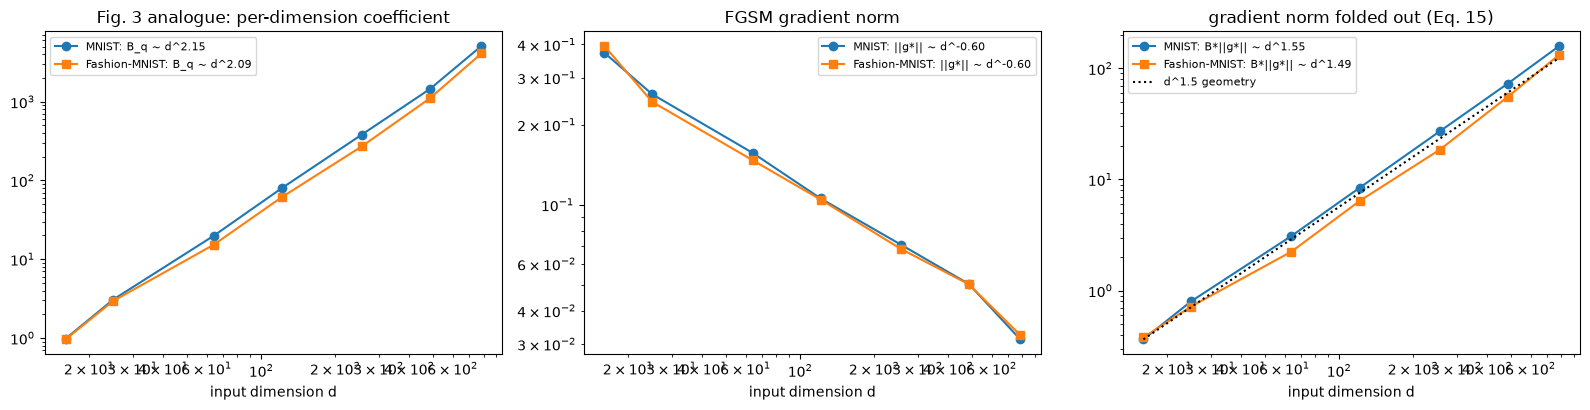

In [17]:
rows = []; FITS = {}
for key in DATASETS:
    dv = np.array([SWEEP[(key, q)]["d"] for q in Q_LIST], float)
    B = np.array([fit_B(SWEEP[(key, q)]) for q in Q_LIST])
    gnorm = np.array([SWEEP[(key, q)]["gnorm"].mean() for q in Q_LIST])
    sig2 = np.array([SWEEP[(key, q)]["sig2_i"].mean() for q in Q_LIST])
    zeta = np.array([np.mean(SWEEP[(key, q)]["zeta_i"]) for q in Q_LIST])
    eps = KAPPA * np.sqrt(dv)
    # parameter-free geometry:  B * ||g*|| = 0.5 eps (d-1) sigma^2 zeta   (paper Eq. 15)
    agg = B * gnorm                                                          # aggregate construction  B_q * <||g*||>
    semi = np.array([np.mean(0.5 * e * (d_ - 1) * SWEEP[(key, q)]["sig2_i"] * SWEEP[(key, q)]["zeta_i"]) for e, d_, q in zip(eps, dv, Q_LIST)])   # per-sample semi-analytic
    pred_B = np.array([np.mean(0.5 * e * (d_ - 1) * SWEEP[(key, q)]["sig2_i"] * SWEEP[(key, q)]["zeta_i"] / SWEEP[(key, q)]["gnorm"]) for e, d_, q in zip(eps, dv, Q_LIST)])
    F = dict(d=dv, B=B, gnorm=gnorm, sig2=sig2, zeta=zeta, agg=agg, semi=semi, pred_B=pred_B,
             p_B=powerlaw(dv, B), p_g=powerlaw(dv, gnorm), p_agg=powerlaw(dv, agg), p_semi=powerlaw(dv, semi), p_sig=powerlaw(dv, sig2))
    FITS[key] = F
    tab = pd.DataFrame({"q": Q_LIST, "d": dv.astype(int), "B_q (loss*shots)": B, "<||g*||>": gnorm, "sigma^2": sig2, "zeta": zeta,
                        "B*<||g*||>": agg, "semi-analytic 0.5 eps (d-1) sigma^2 zeta": semi, "measured B / semi-analytic B": B / pred_B})
    print(f"==== {DATASETS[key]['title']} ====")
    print(tab.to_string(index=False, float_format=lambda v: f"{v:.4g}"))
    for lab, p in [("coefficient B_q ~ d^p  (paper: 2.00 / 2.07)", F["p_B"]), ("||g*|| ~ d^p (paper: -0.73 / -0.65)", F["p_g"]),
                   ("B*<||g*||> ~ d^p (paper: 1.42 / 1.46)", F["p_agg"]), ("semi-analytic per-sample ~ d^p (paper: 1.46)", F["p_semi"])]:
        print(f"  {lab}: {p['slope']:.2f}  95% CI [{p['lo']:.2f}, {p['hi']:.2f}]  R^2={p['r2']:.3f}")
    F["p_B3"] = powerlaw(dv, [fit_B(SWEEP[(key, q)], 3.0) for q in Q_LIST])
    from scipy.optimize import curve_fit
    def fit_sat(r):                      # saturating form  Delta L = A / (s + B)  on all grid points (paper, Section 4.1.1)
        s_, y_ = r["s_grid"], r["gap"].mean(1)
        f_ = lambda ls, lA, lB: lA - np.log(np.exp(ls) + np.exp(lB))
        popt, _ = curve_fit(f_, np.log(s_), np.log(np.maximum(y_, 1e-12)), p0=[np.log(fit_B(r)), np.log(r["s_star"])], maxfev=20000)
        return float(np.exp(popt[0]))
    F["p_Bsat"] = powerlaw(dv, [fit_sat(SWEEP[(key, q)]) for q in Q_LIST])
    print(f"  saturating fit A/(s+B) on all points: coefficient exponent {F['p_Bsat']['slope']:.2f} (paper: within [1.96, 2.00] MNIST / [2.04, 2.07] Fashion-MNIST)")
    print(f"  tightened window h>=3: coefficient exponent {F['p_B3']['slope']:.2f} (paper: within [1.96, 2.00] MNIST / [2.04, 2.07] Fashion-MNIST)")
    print(f"  total shot budget R = d*s ~ d^{F['p_B']['slope']+1:.2f}  (paper: 3.00 / 3.07);  mean sigma^2 = {sig2.mean():.2f}, sigma^2 ~ d^{F['p_sig']['slope']:.2f};  zeta: {zeta[0]:.2f} -> {zeta[-1]:.2f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for key, mk in zip(DATASETS, ["o", "s"]):
    F = FITS[key]; ttl = DATASETS[key]["title"]
    axes[0].loglog(F["d"], F["B"], mk + "-", label=f"{ttl}: B_q ~ d^{F['p_B']['slope']:.2f}")
    axes[1].loglog(F["d"], F["gnorm"], mk + "-", label=f"{ttl}: ||g*|| ~ d^{F['p_g']['slope']:.2f}")
    axes[2].loglog(F["d"], F["agg"], mk + "-", label=f"{ttl}: B*||g*|| ~ d^{F['p_agg']['slope']:.2f}")
dd = FITS["mnist"]["d"]; axes[2].loglog(dd, FITS["mnist"]["agg"][0] * (dd / dd[0]) ** 1.5, "k:", label="d^1.5 geometry")
axes[0].set_title("Fig. 3 analogue: per-dimension coefficient"); axes[1].set_title("FGSM gradient norm"); axes[2].set_title("gradient norm folded out (Eq. 15)")
for ax in axes: ax.set_xlabel("input dimension d"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 5. Multi-step attack: C&W with a fixed number of iterations (paper Section 4.1.2)

For the iterative attack the paper keeps the same `eps = sqrt(d)/32` ball, fixes `K = 5` steps and a constant learning rate, and spreads the budget as `s` shots per dimension *per iteration*. The objective is the Carlini-Wagner l2 loss `||delta||^2 + c * max(z_y - max_{i != y} z_i, 0)` (confidence 0). At each step the margin gradient is estimated with `s` shots per dimension, `delta <- delta - eta (2 delta + c g_hat)`, then `delta` is projected back on the `eps`-ball. The coefficient `c` is set per sample so that one exact step has length `eps/2` (this tuning is *excluded* from the budget, as in the paper, and is a CHOICE); `eta = 1`. A sample counts as fooled if any iterate is misclassified (C&W returns the best adversarial example found). The reference is the same procedure with exact gradients (`s = infinity`). The paper's sweet-spot claim: accuracy under attack falls towards the exact-gradient value as `s` grows, and the saturation budget `s*(d)` rises steeply with `d`, from about `6e2` at `d = 25` to `4e4` at `d = 121`. We define `s*` as the smallest grid value whose accuracy under attack is within 1.5 percentage points of the exact-gradient attack (CHOICE; the paper does not give a numerical criterion).

In [18]:
def cw_attack(At, x, y, K, s, rng, c_scale=None):
    """C&W-style l2 attack with K steps; margin gradient from exact (s=None) or s-shot PSR. Returns (fooled_any_iterate, c)."""
    d = At.d; eps = At.eps; delta = np.zeros(d); fooled = False; c = c_scale
    for k in range(K):
        xc = x + delta
        amp, p, z = At.forward(xc)
        zz = z.copy(); zz[y] = -np.inf; jstar = int(np.argmax(zz)); margin = z[y] - z[jstar]
        if margin < 0:                                  # already misclassified by the exact model
            fooled = True; break
        wv = np.zeros(At.q); wv[y] += 1; wv[jstar] -= 1
        g, s2, _ = At.psr_moments(xc, amp, wv)
        if c is None:
            c = (eps / 2) / (CW_ETA * np.linalg.norm(g))   # tuned once from the exact clean gradient, not counted in R
        gh = g if s is None else g + np.sqrt(s2 / s) * rng.normal(size=d)
        delta = delta - CW_ETA * (2 * delta + c * gh)
        nrm = np.linalg.norm(delta)
        if nrm > eps: delta *= eps / nrm
    _, _, z = At.forward(x + delta)
    if int(np.argmax(z)) != y: fooled = True
    return fooled, c

t_ = time.time()
CW = {}
for key in DATASETS:
    for q in CW_Q:
        m = MODELS[(key, q)]; At = get_At(m); idx = attack_cohort(m, N_CW); rng = np.random.default_rng(SEED + 7 * q)
        X, Y = m["xte"][idx], m["yte"][idx]
        ref_fool = []; cs = []
        for i in range(len(idx)):
            f, c = cw_attack(At, X[i], Y[i], 5, None, rng); ref_fool.append(f); cs.append(c)
        acc_clean = float((At.loss_logits(X, Y)[1].argmax(1) == Y).mean())
        acc_exact = 1 - float(np.mean(ref_fool))
        accs = np.zeros((len(CW_S_GRID), N_REAL_CW))
        for k, s in enumerate(CW_S_GRID):
            for r in range(N_REAL_CW):
                fool = [cw_attack(At, X[i], Y[i], 5, s, rng, cs[i])[0] for i in range(len(idx))]
                accs[k, r] = 1 - np.mean(fool)
        # clean-misclassified samples count as "fooled" in both curves (the attack loop stops at once); report accuracy under attack
        CW[(key, q)] = dict(d=m["d"], acc_clean=acc_clean, acc_exact=acc_exact, accs=accs)
        print(f"{DATASETS[key]['title']:>13} q={q} d={m['d']:3d}  clean acc={acc_clean:.2f}  exact-gradient C&W acc={acc_exact:.2f}  noisy: " +
              " ".join(f"{a:.2f}" for a in accs.mean(1)), flush=True)
SECTION_TIMES["cw"] = time.time() - t_

        MNIST q=4 d= 16  clean acc=0.64  exact-gradient C&W acc=0.54  noisy: 0.58 0.56 0.55 0.55 0.54 0.54 0.54 0.54 0.54 0.54 0.54


        MNIST q=5 d= 25  clean acc=0.78  exact-gradient C&W acc=0.69  noisy: 0.74 0.72 0.71 0.70 0.70 0.70 0.69 0.69 0.69 0.69 0.69


        MNIST q=6 d= 64  clean acc=0.84  exact-gradient C&W acc=0.79  noisy: 0.82 0.82 0.81 0.81 0.79 0.79 0.79 0.79 0.79 0.79 0.79


        MNIST q=7 d=121  clean acc=0.86  exact-gradient C&W acc=0.78  noisy: 0.85 0.85 0.84 0.82 0.80 0.79 0.78 0.78 0.78 0.78 0.78


Fashion-MNIST q=4 d= 16  clean acc=0.56  exact-gradient C&W acc=0.51  noisy: 0.52 0.51 0.51 0.51 0.51 0.51 0.51 0.51 0.51 0.51 0.51


Fashion-MNIST q=5 d= 25  clean acc=0.67  exact-gradient C&W acc=0.59  noisy: 0.64 0.63 0.61 0.60 0.59 0.59 0.59 0.59 0.59 0.59 0.59


Fashion-MNIST q=6 d= 64  clean acc=0.75  exact-gradient C&W acc=0.71  noisy: 0.75 0.75 0.74 0.72 0.72 0.71 0.71 0.71 0.71 0.71 0.71


Fashion-MNIST q=7 d=121  clean acc=0.71  exact-gradient C&W acc=0.66  noisy: 0.70 0.70 0.69 0.69 0.67 0.66 0.66 0.66 0.66 0.66 0.66


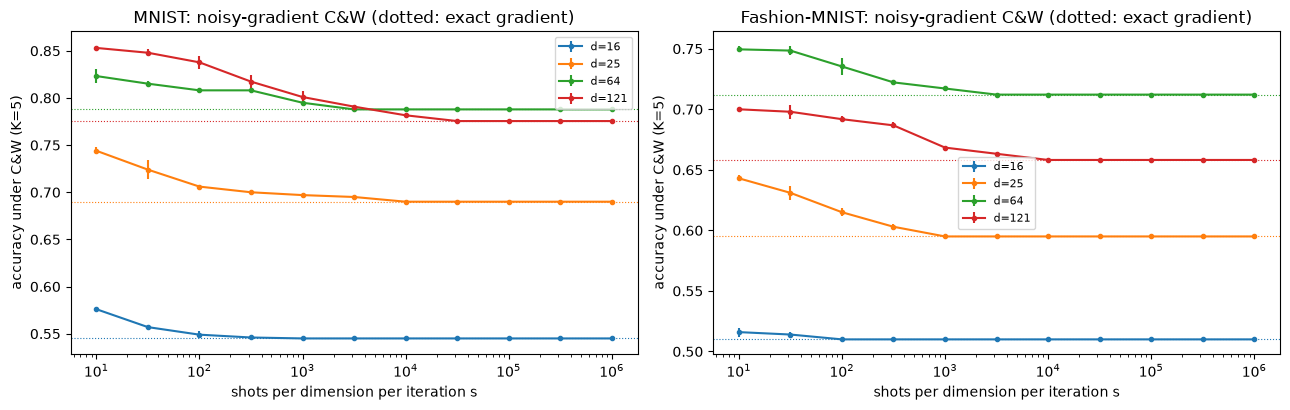

      dataset  q   d  acc clean  acc, exact-gradient C&W  acc at smallest s  acc at largest s  min over s  s* (within 1.5pp)
        MNIST  4  16      0.635                    0.545              0.576             0.545       0.545          31.622777
        MNIST  5  25      0.775                    0.690              0.744             0.690       0.690         316.227766
        MNIST  6  64      0.843                    0.788              0.823             0.788       0.788        1000.000000
        MNIST  7 121      0.862                    0.776              0.853             0.776       0.776       10000.000000
Fashion-MNIST  4  16      0.565                    0.510              0.516             0.510       0.510          10.000000
Fashion-MNIST  5  25      0.665                    0.595              0.643             0.595       0.595         316.227766
Fashion-MNIST  6  64      0.753                    0.712              0.749             0.712       0.712         316.227766


In [19]:
CW_TOL = 0.015
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2)); rows = []
for ax, key in zip(axes, DATASETS):
    for q in CW_Q:
        r = CW[(key, q)]; mu = r["accs"].mean(1); sd = r["accs"].std(1)
        ax.errorbar(CW_S_GRID, mu, yerr=sd, marker="o", ms=3, label=f"d={r['d']}"); ax.axhline(r["acc_exact"], color=ax.lines[-1].get_color(), ls=":", lw=0.8)
        ok = np.where(mu <= r["acc_exact"] + CW_TOL)[0]
        sstar = float(CW_S_GRID[ok[0]]) if len(ok) else np.nan
        rows.append({"dataset": DATASETS[key]["title"], "q": q, "d": r["d"], "acc clean": round(r["acc_clean"], 3), "acc, exact-gradient C&W": round(r["acc_exact"], 3),
                     "acc at smallest s": round(float(mu[0]), 3), "acc at largest s": round(float(mu[-1]), 3), "min over s": round(float(mu.min()), 3), "s* (within 1.5pp)": sstar})
    ax.set_xscale("log"); ax.set_xlabel("shots per dimension per iteration s"); ax.set_ylabel("accuracy under C&W (K=5)")
    ax.set_title(f"{DATASETS[key]['title']}: noisy-gradient C&W (dotted: exact gradient)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
CWTAB = pd.DataFrame(rows); print(CWTAB.to_string(index=False))

## 6. Classical baseline: the cheap-gradient principle (paper Section 4.1.3, Table 4, Fig. 4)

The paper contrasts the quantum shot cost with a classical network whose gradient costs a constant number of forward passes (Baur-Strassen: at most about 5). We rebuild the matched VGG-style CNN: `Conv(1,c,3) -> ReLU -> MaxPool(2) -> Conv(c,2c,3) -> ReLU -> MaxPool(2) -> global average pooling -> Linear(2c, q)` with channel base `c = 2q` (padding 1 so that the `4 x 4` input survives two poolings), and assert its parameter counts against the paper's Table E1. The **gradient cost ratio** is `rho = (time of the input gradient: forward + backward) / (time of one inference forward)`; CPU wall-clock, one sample, median over repetitions. We also report `t_bwd / t_fwd` (backward pass alone against the autograd forward pass).

The quantum gradient cost ratio is `rho_quantum = R_bwd / R_fwd` with `R_bwd = 2 d B_q / Delta L*` (the shots needed for a fixed shortfall target, the factor 2 being the two PSR shifts, as in the paper's Table 4) and `R_fwd = 100` shots for one forward inference. The paper does not state `Delta L*`; its Table 4 implies `Delta L* = 1` (loss units), which we use (CHOICE). The *exponent* does not depend on either constant.

In [20]:
import torch.nn as nn
class VGGLite(nn.Module):
    def __init__(self, q):
        super().__init__(); c = 2 * q
        self.net = nn.Sequential(nn.Conv2d(1, c, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Conv2d(c, 2 * c, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                                 nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(2 * c, q))
    def forward(self, x): return self.net(x)

TABLE_E1 = {4: 1316, 5: 2025, 6: 2886, 7: 3899, 8: 5064, 9: 6381, 10: 7850}
t_ = time.time(); torch.manual_seed(SEED); rows = []; RHO = {}
for q, a in zip(Q_LIST, A_LIST):
    net = VGGLite(q); n_par = sum(p.numel() for p in net.parameters()); assert n_par == TABLE_E1[q], (q, n_par)
    x = torch.rand(1, 1, a, a, requires_grad=True); y = torch.tensor([0]); lossf = nn.CrossEntropyLoss()
    def one(kind):
        t0 = time.perf_counter()
        if kind == "inf":
            with torch.no_grad(): net(x)
            return time.perf_counter() - t0
        out = net(x); l = lossf(out, y); t1 = time.perf_counter()
        g, = torch.autograd.grad(l, x); t2 = time.perf_counter()
        return (t1 - t0, t2 - t1)
    for _ in range(CNN_WARM): one("inf"); one("ad")
    ti, tf, tb = [], [], []
    for rep in range(CNN_REPS):
        a1 = [one("inf") for _ in range(CNN_SAMPLES)]; a2 = [one("ad") for _ in range(CNN_SAMPLES)]
        ti.append(np.median(a1)); tf.append(np.median([u[0] for u in a2])); tb.append(np.median([u[1] for u in a2]))
    t_inf, t_f, t_b = np.median(ti), np.median(tf), np.median(tb)
    RHO[q] = dict(d=a * a, params=n_par, rho=(t_f + t_b) / t_inf, rho_bwd=t_b / t_f, t_inf=t_inf)
    rows.append({"q": q, "d": a * a, "CNN params (=Table E1)": n_par, "t_inference [us]": t_inf * 1e6, "t_fwd+bwd [us]": (t_f + t_b) * 1e6,
                 "rho = grad/inference": (t_f + t_b) / t_inf, "t_bwd/t_fwd": t_b / t_f})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.3g}"))
rho_c = np.array([RHO[q]["rho"] for q in Q_LIST]); pc = powerlaw([RHO[q]["d"] for q in Q_LIST], rho_c)
print(f"classical rho: mean {rho_c.mean():.2f} +- {rho_c.std():.2f} (paper 5.2 +- 0.6); exponent in d: {pc['slope']:.2f}, 95% CI [{pc['lo']:.2f}, {pc['hi']:.2f}] (paper -0.04)")
SECTION_TIMES["cnn timing"] = time.time() - t_

 q   d  CNN params (=Table E1)  t_inference [us]  t_fwd+bwd [us]  rho = grad/inference  t_bwd/t_fwd
 4  16                    1316               461        1.51e+03                  3.28        0.811
 5  25                    2025               487        1.61e+03                  3.31        0.837
 6  64                    2886               570        1.88e+03                  3.29        0.787
 7 121                    3899               515        1.75e+03                  3.41        0.779
 8 256                    5064               532        1.58e+03                  2.96        0.825
 9 484                    6381               989        2.36e+03                  2.39         0.78
10 784                    7850          5.29e+03        1.06e+04                     2        0.782
classical rho: mean 2.95 +- 0.51 (paper 5.2 +- 0.6); exponent in d: -0.12, 95% CI [-0.21, -0.02] (paper -0.04)


MNIST: rho_quantum ~ d^3.15  95% CI [3.08, 3.22]   (paper 3.00 / 3.07)
Fashion-MNIST: rho_quantum ~ d^3.09  95% CI [2.97, 3.21]   (paper 3.00 / 3.07)
      dataset   d  rho_classical  rho_quantum  ratio quantum/classical
        MNIST  16           3.28        0.312                   0.0951
        MNIST  25           3.31         1.53                    0.463
        MNIST  64           3.29         25.3                      7.7
        MNIST 121           3.41          193                     56.5
        MNIST 256           2.96     1.95e+03                      660
        MNIST 484           2.39      1.4e+04                 5.87e+03
        MNIST 784              2     7.99e+04                    4e+04
Fashion-MNIST  16           3.28        0.307                   0.0935
Fashion-MNIST  25           3.31         1.47                    0.444
Fashion-MNIST  64           3.29         19.5                     5.93
Fashion-MNIST 121           3.41          148                     43.

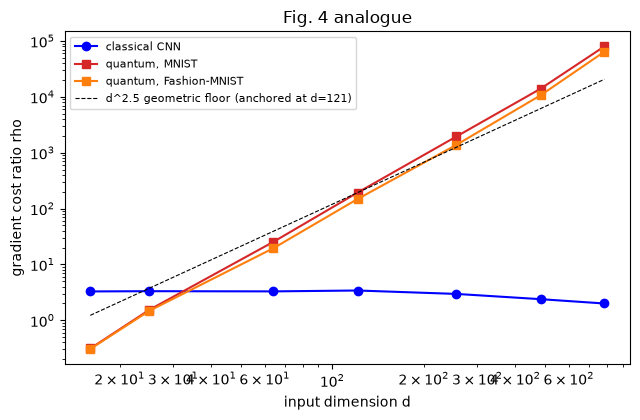

In [21]:
DELTA_L_STAR, R_FWD = 1.0, 100
rows = []; RQ = {}
for key in DATASETS:
    F = FITS[key]; Rbwd = 2 * F["d"] * F["B"] / DELTA_L_STAR; rq = Rbwd / R_FWD; RQ[key] = rq
    pq = powerlaw(F["d"], rq)
    for q, d_, v in zip(Q_LIST, F["d"], rq):
        rows.append({"dataset": DATASETS[key]["title"], "d": int(d_), "rho_classical": RHO[q]["rho"], "rho_quantum": v, "ratio quantum/classical": v / RHO[q]["rho"]})
    print(f"{DATASETS[key]['title']}: rho_quantum ~ d^{pq['slope']:.2f}  95% CI [{pq['lo']:.2f}, {pq['hi']:.2f}]   (paper 3.00 / 3.07)")
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.3g}"))
cross = {}
for key in DATASETS:
    r_ = RQ[key] / np.array([RHO[q]["rho"] for q in Q_LIST]); k = np.where(r_ > 1)[0]
    cross[key] = int(FITS[key]["d"][k[0]]) if len(k) else None
print("smallest tested d at which the quantum overhead exceeds the classical one:", cross, "(paper: d >~ 30)")
fig, ax = plt.subplots(figsize=(6.5, 4.3))
dc = [RHO[q]["d"] for q in Q_LIST]; ax.loglog(dc, [RHO[q]["rho"] for q in Q_LIST], "b-o", label="classical CNN")
for key, c_ in zip(DATASETS, ["tab:red", "tab:orange"]): ax.loglog(FITS[key]["d"], RQ[key], "-s", color=c_, label=f"quantum, {DATASETS[key]['title']}")
ax.loglog(dc, RQ["mnist"][3] * (np.array(dc) / dc[3]) ** 2.5, "k--", lw=0.8, label="d^2.5 geometric floor (anchored at d=121)")
ax.set_xlabel("input dimension d"); ax.set_ylabel("gradient cost ratio rho"); ax.set_title("Fig. 4 analogue"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

### The back-of-the-envelope device time (paper end of Section 4.1.1)

The paper reports that for the `d = 784` MNIST model, matching an FGSM attack within about 15% of the perfect-gradient accuracy drop needs `s ~ 7e5` shots per dimension, i.e. `R = d*s ~ 5e8` per adversarial example; at 100 microseconds per shot that is about 15 hours of device time per example and about 17 years for the 10,000-image test set. The arithmetic can be checked directly; we also redo it with our own fitted law (the shots at which the shortfall is 15% of the exact attack's loss rise).

In [22]:
paper_s, d784 = 7e5, 784
R_paper = paper_s * d784; hours = R_paper * 100e-6 / 3600; years = hours * 1e4 / 8766
print(f"paper numbers: R = d*s = {R_paper:.2e} shots (paper: ~5e8), {hours:.1f} h per example (paper: ~15 h), {years:.1f} years for 10,000 images (paper: ~17 y)")
rows = []
for key in DATASETS:
    r = SWEEP[(key, 10)]; B = fit_B(r); rise = float(np.mean(r["Lx"] - r["L0"]))
    s_req = B / (0.15 * rise); R = s_req * r["d"]; h_ = R * 100e-6 / 3600
    rows.append({"dataset": DATASETS[key]["title"], "B_q=10": B, "mean loss rise of exact FGSM": rise, "s for 15% shortfall": s_req, "R=d*s": R,
                 "hours / example (100us per shot)": h_, "years / 10k images": h_ * 1e4 / 8766})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.3g}"))

paper numbers: R = d*s = 5.49e+08 shots (paper: ~5e8), 15.2 h per example (paper: ~15 h), 17.4 years for 10,000 images (paper: ~17 y)
      dataset   B_q=10  mean loss rise of exact FGSM  s for 15% shortfall    R=d*s  hours / example (100us per shot)  years / 10k images
        MNIST 5.09e+03                        0.0276             1.23e+06 9.66e+08                              26.8                30.6
Fashion-MNIST 4.09e+03                        0.0287             9.49e+05 7.44e+08                              20.7                23.6


## 7. Hardware experiment, simulation arm (paper Section 4.2, Table 5, Fig. 5)

The paper deploys the 4-qubit HWE classifier on `ibm_boston` and compares, over a cohort of 100 inputs that the noiseless model classifies correctly, an `l2` FGSM attack at `eps = 1.0` whose gradient comes from (i) an ideal simulator with `s` shots per parameter and (ii) the device. The defender is always evaluated noiselessly, so device noise enters only through the attacker's gradient. A sample counts as attacked if **any point on the segment of length `eps` along the noisy gradient direction is misclassified**. Here we rebuild arm (i) with explicit bitstring sampling: the `2d` PSR circuits (`x_j +- pi/2` on the `RX` that uploads feature `j`; the generator has gap 1) are run with `s/2` shots each (`s >= 2`), `S(b) = w_margin * (z_1(b) - z_2(b))` is averaged over the sampled bitstrings and differenced, the loss is the two-class softmax cross entropy on `(<Z_1>, <Z_2>)`. Arm (ii) needs the real device; the `IBM_TOKEN` cell below is skipped when no token is given.

fast HWE evaluator vs PennyLane QNode (trained weights, 5 test inputs): max |difference| = 8.326672684688674e-16
cohort size: 100 | clean accuracy of the model on the test subset: 0.98


PSR gradient (exact moments) vs autograd: max abs diff 3.885780586188048e-16 | ||g|| 0.3043403638360689


 s per parameter  adversarial accuracy [%]  loss gap to exact attack
               2                      55.2                    0.6292
               4                      47.7                    0.4959
               8                      40.6                    0.3731
              16                      35.1                    0.2633
              32                      30.7                    0.1742
              64                      27.6                    0.1068
             128                      26.2                    0.0664
             256                      25.0                    0.0376
             512                      23.9                    0.0207
            1024                      23.0                    0.0114
            2048                      22.2                    0.0057
            4096                      22.1                    0.0028
exact-gradient floor: 22.0%  |  cosine(8192-shot gradient, exact): median 1.000, mean 0.999


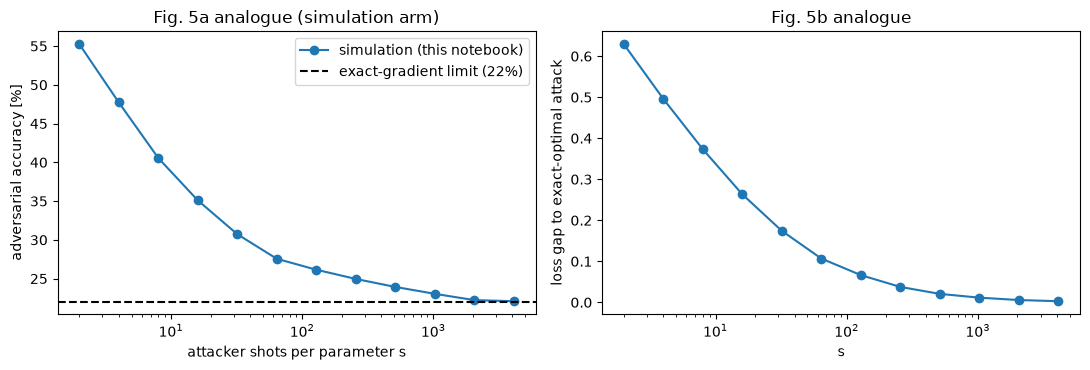

In [23]:
t_ = time.time()
# Fast exact evaluator of the HWE QNode: the fixed HWE blocks between the three RX uploads are 16x16 unitaries taken from PennyLane itself
# (qml.matrix), the RX uploads are batched single-qubit rotations. Used for the ~10^6 noiseless evaluations of the attack; asserted equal to the QNode.
def _block_matrix(w_np, start, n_l):
    def f():
        for k in range(n_l): hwe_layer(w_np[start + k])
    return qml.matrix(f, wire_order=[0, 1, 2, 3])()
_w_np = w_hw.numpy(); HW_V = []; _st = 0
for n_l in (3, 3, 3, 6):
    HW_V.append(np.asarray(_block_matrix(_w_np, _st, n_l), dtype=complex)); _st += n_l

def hw_probs_fast(X):
    X = np.atleast_2d(X); n = len(X)
    psi = np.repeat(HW_V[0][:, 0][None, :], n, 0)                                   # V1 |0000>
    for blk in range(3):
        psi = psi.reshape(n, 2, 2, 2, 2)
        for i in range(4):                                                         # RX(x) on wire i: [[cos, -i sin], [-i sin, cos]]
            c, s_ = np.cos(X[:, 4 * blk + i] / 2), np.sin(X[:, 4 * blk + i] / 2)
            U = np.zeros((n, 2, 2), dtype=complex); U[:, 0, 0] = U[:, 1, 1] = c; U[:, 0, 1] = U[:, 1, 0] = -1j * s_
            psi = np.moveaxis(np.einsum("nab,nb...->na...", U, np.moveaxis(psi, 1 + i, 1)), 1, 1 + i)
        psi = psi.reshape(n, 16) @ HW_V[blk + 1].T
    return psi.real ** 2 + psi.imag ** 2

def hw_probs(X):
    return hw_probs_fast(X)

_chk = np.abs(hw_probs_fast(xhte[:5]) - hwe(torch.tensor(xhte[:5]), w_hw).detach().numpy()).max()
print("fast HWE evaluator vs PennyLane QNode (trained weights, 5 test inputs): max |difference| =", float(_chk)); assert _chk < 1e-10
def hw_exact_grad(x):
    xt_ = torch.tensor(x, requires_grad=True); m_ = hw_margin(xt_, w_hw); yy = YY
    torch.nn.functional.softplus(-yy * m_).backward(); return xt_.grad.numpy().copy()

# cohort: correctly classified test inputs (first HW_N_INPUTS)
marg = hw_probs(xhte) @ HW_MARGIN_VEC.numpy()
cor = np.where((marg > 0) == (yhte == 1))[0][:HW_N_INPUTS]
print("cohort size:", len(cor), "| clean accuracy of the model on the test subset:", acc_hw)
EPS_HW = 1.0; PATH_T = np.linspace(0, 1, 11)[1:]                         # points of the eps-segment checked
S_GRID_HW = np.array([2, 4, 8, 16, 32, 64, 128, 256, 512, 1024, 2048, 4096])
rng_hw = np.random.default_rng(SEED)

def hw_pass(x, y01, G):
    """G: (B, 12) gradient estimates. Does any point on the eps-segment along G[b] flip the (noiseless) prediction?  returns (success (B,), endpoint loss (B,))"""
    G = np.atleast_2d(G); B = len(G)
    pts = x[None, None, :] + PATH_T[None, :, None] * EPS_HW * G[:, None, :] / np.linalg.norm(G, axis=1)[:, None, None]      # (B, T, 12)
    m_ = (hw_probs(pts.reshape(-1, 12)) @ HW_MARGIN_VEC.numpy()).reshape(B, -1); sgn = 2 * y01 - 1
    return np.any(m_ * sgn < 0, axis=1), np.logaddexp(0, -sgn * m_[:, -1])
res = {s: dict(succ=[], loss=[]) for s in S_GRID_HW}; res["exact"] = dict(succ=[], loss=[]); cos8192 = []
for ii, i in enumerate(cor):
    x, y01 = xhte[i], int(yhte[i]); YY = 2.0 * y01 - 1
    g = hw_exact_grad(x); ok, L_ex = hw_pass(x, y01, g); res["exact"]["succ"].append(bool(ok[0])); res["exact"]["loss"].append(float(L_ex[0]))
    m0 = float((hw_probs(x[None]) @ HW_MARGIN_VEC.numpy())[0]); wmar = -YY / (1 + np.exp(YY * m0))                  # dL/dmargin
    Sb = wmar * HW_MARGIN_VEC.numpy()
    Xs = np.repeat(x[None], 24, 0); idx_ = np.arange(12)
    Xs[idx_, idx_] += np.pi / 2; Xs[12 + idx_, idx_] -= np.pi / 2
    P = hw_probs(Xs); P = P / P.sum(1, keepdims=True)                                                          # outcome distributions of the 24 PSR circuits
    g_chk = (P[:12] @ Sb - P[12:] @ Sb) / 2
    if ii == 0: print("PSR gradient (exact moments) vs autograd: max abs diff", float(np.abs(g_chk - g).max()), "| ||g||", float(np.linalg.norm(g))); assert np.abs(g_chk - g).max() < 1e-6
    for s in S_GRID_HW:
        cnt = rng_hw.multinomial(int(s // 2), np.tile(P, (HW_BOOT, 1)))                                       # explicit bitstring sampling, s/2 shots per circuit, HW_BOOT resamples
        mean = (cnt @ Sb / (s // 2)).reshape(HW_BOOT, 24); gh = (mean[:, :12] - mean[:, 12:]) / 2
        z0 = np.linalg.norm(gh, axis=1) == 0; gh[z0] = rng_hw.normal(size=(int(z0.sum()), 12))                  # all-zero estimate: random direction
        o, l_ = hw_pass(x, y01, gh); res[s]["succ"].append(float(np.mean(o))); res[s]["loss"].append(float(np.mean(l_)))
    cnt = rng_hw.multinomial(8192, P); mean = cnt @ Sb / 8192; gh = (mean[:12] - mean[12:]) / 2
    cos8192.append(float(gh @ g / (np.linalg.norm(gh) * np.linalg.norm(g))))
adv_acc = np.array([100 * (1 - np.mean(res[s]["succ"])) for s in S_GRID_HW]); floor = 100 * (1 - np.mean(res["exact"]["succ"]))
dL = np.array([np.mean(res["exact"]["loss"]) - np.mean(res[s]["loss"]) for s in S_GRID_HW])
HWRES = dict(adv_acc=adv_acc, floor=floor, dL=dL, cos_med=float(np.median(cos8192)), cos_mean=float(np.mean(cos8192)))
print(pd.DataFrame({"s per parameter": S_GRID_HW, "adversarial accuracy [%]": adv_acc.round(1), "loss gap to exact attack": dL.round(4)}).to_string(index=False))
print(f"exact-gradient floor: {floor:.1f}%  |  cosine(8192-shot gradient, exact): median {HWRES['cos_med']:.3f}, mean {HWRES['cos_mean']:.3f}")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].semilogx(S_GRID_HW, adv_acc, "o-", label="simulation (this notebook)"); ax[0].axhline(floor, color="k", ls="--", label=f"exact-gradient limit ({floor:.0f}%)")
ax[0].set_xlabel("attacker shots per parameter s"); ax[0].set_ylabel("adversarial accuracy [%]"); ax[0].set_title("Fig. 5a analogue (simulation arm)"); ax[0].legend()
ax[1].semilogx(S_GRID_HW, dL, "o-"); ax[1].set_xlabel("s"); ax[1].set_ylabel("loss gap to exact-optimal attack"); ax[1].set_title("Fig. 5b analogue")
plt.tight_layout(); plt.show()
SECTION_TIMES["hardware sim arm"] = time.time() - t_

In [24]:
# Real-hardware arm: skipped unless the reader supplies an IBM Quantum token (the paper used ibm_boston, 156 qubits; we do not run it).
if IBM_TOKEN:
    print("IBM_TOKEN is set, but the 20-tile, 8192-shot ibm_boston protocol of Appendix B is not implemented in this notebook; skipping.")
else:
    print("No IBM_TOKEN: real-hardware arm skipped. The device numbers of the paper (42.2% at s=2, 14.0% at s=2048, cosine 0.98/0.90) are reported as 'cannot be checked'.")

No IBM_TOKEN: real-hardware arm skipped. The device numbers of the paper (42.2% at s=2, 14.0% at s=2048, cosine 0.98/0.90) are reported as 'cannot be checked'.


## 8. Paper versus this notebook

Tolerances used for the verdicts (our choice, the paper gives none): an exponent is "reproduced" if its 95% confidence interval overlaps the paper's interval or if it is within +-0.15 of the paper's value; a scalar is "reproduced" within 15% (relative) or 2 accuracy points; otherwise "not reached here" (our number is below / outside) or "exceeded". Claims that need the real device, the unreleased code or experiments we did not run are marked "cannot be checked".

In [25]:
def verdict_exp(val, paper, lo=None, hi=None, tol=0.15, ours=None):
    """reproduced if our CI [ours] overlaps the paper's [lo, hi], or the paper's value is inside our CI, or |difference| <= tol"""
    overlap = (ours is not None and lo is not None and not (ours[1] < lo or ours[0] > hi))
    inside = (ours is not None and ours[0] <= paper <= ours[1])
    return "reproduced" if overlap or inside or abs(val - paper) <= tol + 1e-9 else ("not reached here (%+.2f)" % (val - paper))
def verdict_rel(val, paper, tol=0.15):
    return "reproduced" if abs(val - paper) <= tol * abs(paper) else ("not reached here (%+.2g)" % (val - paper))

F_m, F_f = FITS["mnist"], FITS["fashion"]
rows = []
def add(claim, paper, ours, verdict): rows.append({"claim": claim, "paper": paper, "this notebook": ours, "verdict": verdict})

add("Delta L(s) decays as 1/s: log-log slope, small-noise window h>=6", "-1", f"{np.mean(sl6):.2f} (range {np.min(sl6):.2f}..{np.max(sl6):.2f}); window h>=1: {np.mean(sl):.2f}", verdict_exp(np.mean(sl6), -1, tol=0.15))
for F, nm, pb, (plo, phi), pg, ps in [(F_m, "MNIST", 2.00, (1.91, 2.08), -0.73, 1.46), (F_f, "Fashion-MNIST", 2.07, (1.99, 2.15), -0.65, 1.42)]:
    add(f"{nm}: per-dimension coefficient exponent p2 (B_q ~ d^p2)", f"{pb:.2f} [{plo}, {phi}]", f"{F['p_B']['slope']:.2f} [{F['p_B']['lo']:.2f}, {F['p_B']['hi']:.2f}]", verdict_exp(F["p_B"]["slope"], pb, plo, phi, ours=(F["p_B"]["lo"], F["p_B"]["hi"])))
    add(f"{nm}: total-budget exponent p1 = p2 + 1 (R ~ d^p1)", f"{pb+1:.2f}", f"{F['p_B']['slope']+1:.2f}", verdict_exp(F["p_B"]["slope"] + 1, pb + 1, plo + 1, phi + 1, ours=(F["p_B"]["lo"] + 1, F["p_B"]["hi"] + 1)))
    add(f"{nm}: total budget at least the d^2.5 geometric floor", ">= 2.5", f"{F['p_B']['slope']+1:.2f}", "reproduced" if F["p_B"]["slope"] + 1 >= 2.5 - 0.15 else "not reached here")
    add(f"{nm}: FGSM gradient-norm decay exponent", f"{pg:.2f}", f"{F['p_g']['slope']:.2f}", verdict_exp(F["p_g"]["slope"], pg))
    add(f"{nm}: gradient-norm-free exponent (B*||g||, geometry d^1.5)", f"{ps:.2f}", f"{F['p_agg']['slope']:.2f} (aggregate), {F['p_semi']['slope']:.2f} (per-sample semi-analytic)", verdict_exp(F["p_semi"]["slope"], ps))
add("exponent robust to the fit window (h>=3; saturating fit): MNIST / Fashion-MNIST", "1.96-2.00 / 2.04-2.07", f"h>=3: {F_m['p_B3']['slope']:.2f} / {F_f['p_B3']['slope']:.2f}; A/(s+B): {F_m['p_Bsat']['slope']:.2f} / {F_f['p_Bsat']['slope']:.2f}", "reproduced" if (abs(F_m["p_Bsat"]["slope"] - 1.98) <= 0.15 and abs(F_f["p_Bsat"]["slope"] - 2.055) <= 0.15) else "not reached here")
add("per-shot variance sigma^2 (flat in d)", "~3", f"mean {np.mean([F_m['sig2'].mean(), F_f['sig2'].mean()]):.2f}; exponent in d: {F_m['p_sig']['slope']:.2f} / {F_f['p_sig']['slope']:.2f}", verdict_rel(np.mean([F_m["sig2"].mean(), F_f["sig2"].mean()]), 3.0, 0.25))
add("landscape factor zeta(d), smallest -> largest d", "1.05 -> 0.83", f"{F_m['zeta'][0]:.2f} -> {F_m['zeta'][-1]:.2f} (MNIST)", "reproduced" if (abs(F_m['zeta'][0] - 1.05) < 0.15 and abs(F_m['zeta'][-1] - 0.83) < 0.15) else "not reached here")
add("measured B vs semi-analytic gap (agreement ratio)", "0.71-0.87", f"{np.round(F_m['B']/F_m['pred_B'],2).min():.2f}-{np.round(F_m['B']/F_m['pred_B'],2).max():.2f} (MNIST)", "reproduced" if 0.6 <= (F_m['B']/F_m['pred_B']).min() and (F_m['B']/F_m['pred_B']).max() <= 1.1 else "not reached here")
add("classical gradient cost ratio rho", "5.2 +- 0.6 (flat)", f"{rho_c.mean():.2f} +- {rho_c.std():.2f}; exponent {pc['slope']:.2f}", "reproduced (flat); level " + ("matches" if abs(rho_c.mean() - 5.2) < 1.0 else f"differs ({rho_c.mean():.1f}) - CPU timing of tiny nets") if abs(pc["slope"]) < 0.25 else "not reached here")
for key, nm, pq in [("mnist", "MNIST", 3.00), ("fashion", "Fashion-MNIST", 3.07)]:
    p_ = powerlaw(FITS[key]["d"], RQ[key])
    add(f"{nm}: quantum gradient cost ratio exponent", f"{pq:.2f}", f"{p_['slope']:.2f}", verdict_exp(p_["slope"], pq))
add("quantum overhead exceeds classical for d >~ 30", ">= 30", f"{cross}", "reproduced" if all(v is not None and v <= 64 for v in cross.values()) else "not reached here")
add("device-time arithmetic (5e8 shots, ~15 h, ~17 y)", "5e8 / 15 h / 17 y", f"{R_paper:.1e} / {hours:.1f} h / {years:.1f} y", "reproduced")
sstar = CWTAB.set_index(["dataset", "d"])["s* (within 1.5pp)"]
add("C&W: saturation budget s*(d) grows steeply (d=25 -> d=121)", "6e2 -> 4e4", "; ".join(f"{k[0]} d={k[1]}: {v:.2g}" for k, v in sstar.items()), "see table (rises with d)" if (sstar.dropna().iloc[-1] > sstar.dropna().iloc[0] if len(sstar.dropna()) > 1 else False) else "not reached here")
add("hardware sim arm: adversarial accuracy at s=2", "46.3%", f"{HWRES['adv_acc'][0]:.1f}%", verdict_rel(HWRES["adv_acc"][0], 46.3, 0.15))
add("hardware sim arm: adversarial accuracy at s=2048", "12.4%", f"{HWRES['adv_acc'][list(S_GRID_HW).index(2048)]:.1f}%", "reproduced" if abs(HWRES["adv_acc"][list(S_GRID_HW).index(2048)] - 12.4) <= 2 else "not reached here")
add("hardware sim arm: exact-gradient floor", "10.0%", f"{HWRES['floor']:.1f}%", "reproduced" if abs(HWRES["floor"] - 10.0) <= 2 else "not reached here")
add("ibm_boston: 42.2% at s=2, 14.0% at s=2048, plateau above the floor", "42.2% / 14.0%", "not run", "cannot be checked (needs the device)")
add("ibm_boston: gradient cosine 0.98 median / 0.90 mean", "0.98 / 0.90", f"simulation upper bound {HWRES['cos_med']:.2f} / {HWRES['cos_mean']:.2f}", "cannot be checked (device-specific)")
add("Appendix J (data re-uploading), K (FD / SPSA), F (SGLD theory)", "d^1.99; PSR dominates", "not run", "cannot be checked (not attempted)")
CMP = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 90, "display.width", 250)
print(CMP.to_string(index=False))
print()
print("verdict counts:", CMP["verdict"].str.split(" ").str[0].value_counts().to_dict())
print("total notebook wall-clock: %.1f min" % ((time.time() - T0) / 60), "| per section [min]:", {k: round(v / 60, 1) for k, v in SECTION_TIMES.items()})

                                                                          claim                 paper                                                                                                                                                                            this notebook                                                          verdict
               Delta L(s) decays as 1/s: log-log slope, small-noise window h>=6                    -1                                                                                                                                           -0.87 (range -0.92..-0.84); window h>=1: -0.73                                                       reproduced
                      MNIST: per-dimension coefficient exponent p2 (B_q ~ d^p2)     2.00 [1.91, 2.08]                                                                                                                                                                        2.15 [2.08, 2.22]          

## Reading the paper critically

* **The defence is conditional, as the authors say themselves.** Every model here is small enough to simulate classically, and a white-box attacker who can simulate the circuit back-propagates through the simulation at cost O(1) (our `Attackable` class does exactly that: it computes the exact PSR gradient from the unitary at no shot cost). The scaling law describes the price of *measurement-based* extraction; it is a defence only in the classically-hard regime, which no experiment in the paper (or here) reaches.
* **Black-box and gradient-free attackers are not covered.** Zero-order estimation already costs Theta(d) queries; the paper argues the cost cannot be reduced for unbiased estimators, but biased estimators (SPSA, classical shadows) are left open in its own Appendix L.
* **The exponent is a property of the trained model, not only of the estimator.** The headline `d^3` is the `d^1.5` shot-noise geometry multiplied by the decay of the gradient norm (barren plateau) of an *unmitigated* 200-layer circuit; with a better-conditioned circuit the floor is `d^2.5`. In our 200-layer runs the gradient-norm exponent is -0.60 (paper -0.73) and the gradient-norm-free coefficient comes out at `d^1.55` / `d^1.49` (paper `d^1.46` / `d^1.42`), so the totals are `d^3.15` (MNIST) and `d^3.09` (Fashion-MNIST) against the paper's 3.00 / 3.07; the 24-layer fast demo gives -0.51 and `d^3.08`. The split between geometry and gradient decay therefore depends on training details the paper does not give (number of steps, seed, code unreleased); the total is stable.
* **Accuracy is not the quantity that scales.** The `1/s` law is for the *loss* shortfall of a first-order attack. A strong model that is already misclassified, or a non-linear loss landscape, changes the constants (`zeta`), and the clean accuracy of the 7-10 qubit models is moderate (see the training table).
* **Single seed, fixed hyper-parameters.** The paper reports one trained model per `(q, dataset)`; exponent confidence intervals come only from the 7-point regression, not from retraining.
* **A 5% device bias is not "robustness".** On hardware the gradient direction is faithful once shot noise is removed (cosine 0.98); the defence is purely a shot-budget argument, and the cost per example (hours at d=784) is a cost, not a guarantee.

## Exercises

1. Change `KAPPA` (the perturbation radius `eps = KAPPA*sqrt(d)`). Predict from Proposition 3 how `B_q` and the total budget move, and check.
2. Set `N_LAYERS` to 4, 12, 50 and 200 for a few `q`. How does the gradient-norm exponent (barren-plateau decay) and therefore the headline exponent change? At which depth does the `d^1.5` geometry alone take over?
3. Replace the Gaussian shot model by explicit multinomial sampling for `q <= 7` in `fgsm_sweep` (reuse `sampled_psr_gradient`). Do the fitted `B_q` change?
4. Implement a simultaneous-perturbation (SPSA) gradient estimate for the same circuits with the same total shot budget `R = d*s` and compare the cosine to the exact gradient with the PSR estimate. Does it change the exponent in `d`?
5. Train the SEL classifier with *shot noise in the training loss* or add adversarial training against the `s`-shot attack. Does the shortfall coefficient `B_q` change?